# CV Project: Linus Torvalds Group

**University of Pisa** — Master's Degree in Artificial Intelligence and Data Engineering

*Multimedia Information Retrieval and Computer Vision*

**Group Members:** Domenico Lenzerini, Alessandro Lagonegro, Ferdinando Muraca, Carlo Vincenzo Stanzione

## Environment Configuration

Setup of deterministic CUDA flags (`:4096:8`) and fixed hashing seeds to prevent hardware-dependent variations in gradient computation.

In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 27.0 MB/s eta 0:00:00


In [ ]:
# --- Environment Configuration ---
import os

# Configure CUDA for deterministic operations (required for reproducibility)
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

# Set fixed hash seed for consistent dictionary iteration order
os.environ["PYTHONHASHSEED"] = "1234"

In [ ]:
# --- Standard Python Libraries ---
import sys
import zipfile
import gc
import copy
import random
import time
import shutil
import urllib.request
from pathlib import Path

# --- Data Science, Statistics and Visualization ---
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score
)
from sklearn import decomposition
from sklearn import manifold
import pandas as pd

# --- Image Processing ---
import cv2
import requests

# --- Deep Learning (PyTorch) ---
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.models as models
import torchvision.transforms as T
from torchvision import datasets
from torch.utils.data import Dataset, Subset, DataLoader

# --- Object Detection ---
from ultralytics import YOLO

# --- External Utilities ---
from tqdm.notebook import trange, tqdm

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


## Dataset Acquisition Pipeline

Automated script to retrieve the dataset and checkpoints from remote storage. Implements a check-and-fetch logic: it downloads and extracts the archive only if the target directories `data/NA_Fish_Dataset` and `checkpoints` are missing or empty

In [ ]:
# --- Dataset Download and Extraction ---

DATA_ROOT = Path("data/NA_Fish_Dataset")
DATASET_FOLDER_URL = "https://drive.google.com/drive/folders/1yns5ojdCgbhheOOAwkNm1DW7hkX2tBjI"

# Verify if the dataset is already extracted and populated
if DATA_ROOT.exists() and any(DATA_ROOT.iterdir()):
    print("Dataset already present:", DATA_ROOT.resolve())
else:
    # Download compressed dataset archive from Google Drive
    print("Downloading dataset from Google Drive...")
    DATA_ROOT.parent.mkdir(parents=True, exist_ok=True)
    !gdown --folder "{DATASET_FOLDER_URL}" -O data/ --quiet

    # Extract dataset archives
    print("Extracting dataset...")
    for zip_file in Path("data").rglob("*.zip"):
        print(f"  Extracting {zip_file.name}...")
        with zipfile.ZipFile(zip_file, "r") as z:
            z.extractall(DATA_ROOT)
        zip_file.unlink()

    print("Dataset extracted to:", DATA_ROOT.resolve())

Extracting dataset...
  Extracting NA_Fish_Dataset.zip...
Dataset extracted to: /content/data/NA_Fish_Dataset


In [ ]:
# Reference checkpoints for reproducibility (pre-trained models)

CHECKPOINTS_DIR = Path("checkpoints")
CHECKPOINTS_FOLDER_URL = "https://drive.google.com/drive/folders/1RPNLAIjObd2y5y9TnuN2zGuCUcRKQv9k"

if not CHECKPOINTS_DIR.exists() or not any(CHECKPOINTS_DIR.glob("*.pt")):
    print("Downloading reference checkpoints from Google Drive...")
    CHECKPOINTS_DIR.mkdir(parents=True, exist_ok=True)
    !gdown --folder "{CHECKPOINTS_FOLDER_URL}" -O {CHECKPOINTS_DIR} --quiet

    # Extract checkpoint archives
    print("Extracting checkpoints...")
    for zip_file in CHECKPOINTS_DIR.glob("*.zip"):
        print(f"  Extracting {zip_file.name}...")
        with zipfile.ZipFile(zip_file, "r") as z:
            z.extractall(CHECKPOINTS_DIR)
        zip_file.unlink()

    print(f"Checkpoints saved to: {CHECKPOINTS_DIR.resolve()}")
else:
    print(f"Checkpoints already present: {CHECKPOINTS_DIR.resolve()}")

# --- Reference Checkpoint Paths ---
# These paths are used when USE_REFERENCE_* = True
REF_MLP_GRID = CHECKPOINTS_DIR / "mlp-grid-best-reference.pt"
REF_MLP_MODEL = CHECKPOINTS_DIR / "mlp-model-reference.pt"
REF_VGG_GRID = CHECKPOINTS_DIR / "vgg-grid-best-reference.pt"
REF_VGG_MODEL = CHECKPOINTS_DIR / "vgg-model2-reference.pt"
REF_VGG_PRETRAINED_GRID = CHECKPOINTS_DIR / "vgg-pretrained-grid-best-reference.pt"
REF_VGG_PRETRAINED_MODEL = CHECKPOINTS_DIR / "vgg-pretrained-model-reference.pt"

Extracting checkpoints...
Checkpoints saved to: /content/checkpoints


## Reproducibility Protocol

To mitigate stochasticity in neural network training (e.g., weight initialization, CUDA kernels), the following constraints are enforced:

* **Global Seeding**: Fixed seed (`1234`) applied to `random`, `numpy`, and `torch`.
* **CuDNN Determinism**: Forces deterministic convolution algorithms (`deterministic=True`) and disables heuristic benchmarking (`benchmark=False`).

In [ ]:
# --- Seed Configuration for Reproducibility ---
SEED = 1234

# Seed all random number generators for reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Force deterministic algorithms (trades speed for reproducibility)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)

# --- Environment Information ---
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("PyTorch CUDA build:", torch.version.cuda)
print("cuDNN:", torch.backends.cudnn.version())
print("CUDA available:", torch.cuda.is_available())

# Device selection (GPU preferred for ~10-100x speedup)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("Compute Capability:", torch.cuda.get_device_capability(0))
    print("Supported Architectures:", torch.cuda.get_arch_list())
    try:
        print("Driver Version:", torch._C._cuda_getDriverVersion())
        print("Compiled CUDA Version:", torch._C._cuda_getCompiledVersion())
    except Exception as e:
        print("Driver/compiled version query failed:", e)

Python: 3.12.12
PyTorch: 2.9.0+cu126
PyTorch CUDA build: 12.6
cuDNN: 91002
CUDA available: True
Device: cuda
GPU: Tesla T4
Compute Capability: (7, 5)
Supported Architectures: ['sm_50', 'sm_60', 'sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90']
Driver/compiled version query failed: module 'torch._C' has no attribute '_cuda_getDriverVersion'


# Data Preprocessing Pipeline

Transformation sequence converting raw images into training-ready tensors.
1.  **Acquisition**: Automated retrieval.
2.  **Partitioning**: Stratified split (Train 64% / Val 16% / Test 20%).
3.  **Normalization**: Standardization ($\mu, \sigma$) based on training statistics.
4.  **Augmentation**: Dual strategy (Stochastic transforms + Deterministic expansion).

## Dataset Specifications

The project utilizes a subset of the **Large-Scale Fish Dataset**, focusing on a **fine-grained classification** task. The challenge lies in the low inter-class variance, requiring the model to learn subtle discriminative features (e.g., fin shape, scale patterns).

**Summary Statistics:**

| Property | Description |
| :--- | :--- |
| **Domain** | Marine Biology / Seafood Classification |
| **Input Data** | RGB Images (Variable Resolution) |
| **Taxonomy** | 9 Distinct Classes |
| **Task Type** | Fine-grained Image Classification |

**Classes:**
*Black Sea Sprat, Gilt Head Bream, Horse Mackerel, Red Mullet, Red Sea Bream, Sea Bass, Shrimp, Striped Red Mullet, Trout.*

In [ ]:
# Lettura delle imaggini row dal dataset, e ci viene applicato il label a seconda della cartella in cui si trovano, ogni immagine è una matrice (H x W x C)
base_ds = datasets.ImageFolder(root=str(DATA_ROOT), transform=None) 

# Extract targets as numpy array for sklearn's train_test_split
targets = np.array(base_ds.targets)
n = len(base_ds)

print("Total images:", n, "| Number of classes:", len(base_ds.classes))
print("Classes:", base_ds.classes)

Total images: 430 | Number of classes: 9
Classes: ['Black Sea Sprat', 'Gilt Head Bream', 'Horse Mackerel', 'Red Mullet', 'Red Sea Bream', 'Sea Bass', 'Shrimp', 'Striped Red Mullet', 'Trout']


## Data Partitioning Strategy

A **Stratified Hold-Out Validation** preserves class distribution across subsets.
1.  **Test**: 20% isolated for final evaluation.
2.  **Val/Train**: Remaining 80% split into Validation (20%) and Training.

**Final Distribution:**
$$N_{train} \approx 64\%, \quad N_{val} \approx 16\%, \quad N_{test} = 20\%$$

In [ ]:
# --- Stratified Train/Validation/Test Split ---

all_idx = np.arange(n)

# Stage 1: Reserve 20% for test (stratified by class)
train_idx, test_idx = train_test_split(
    all_idx, test_size=0.2, random_state=SEED, stratify=targets
)

# Stage 2: Split remaining 80% into train/val (64%/16% overall)
train_idx, val_idx = train_test_split(
    train_idx, test_size=0.2, random_state=SEED, stratify=targets[train_idx]
)

print("Train:", len(train_idx), "| Validation:", len(val_idx), "| Test:", len(test_idx))

Train: 275 | Validation: 69 | Test: 86


## Normalization Statistics

Standardization parameters ($\mu, \sigma$) are computed **exclusively on the Training Set** to prevent data leakage. A two-pass algorithm (Sum $\rightarrow$ Variance) is used to handle the dataset incrementally without memory overload.

In [ ]:
# Done to stabilize the network, so that neurons know the range of the input they receive
# normalization done for each channel (R, G, B) using the computed mean and std

# --- DataLoader Configuration ---
# Enable pinned memory for faster CPU→GPU transfers when using CUDA
PIN_MEMORY = (device.type == "cuda")


def compute_mean_std(dataset, batch_size=32, num_workers=2):
    """
    Computes per-channel mean and standard deviation of a dataset.

    Uses two-pass approach: first compute mean, then compute variance.
    This ensures mathematically correct statistics.
    """
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=PIN_MEMORY)

    # First pass: compute mean
    pixel_sum = torch.zeros(3)
    pixel_count = 0

    for x, _ in tqdm(loader, desc="Computing mean", leave=False):
        pixel_sum += x.sum(dim=(0, 2, 3))
        pixel_count += x.shape[0] * x.shape[2] * x.shape[3]

    mean = pixel_sum / pixel_count

    # Second pass: compute variance
    var_sum = torch.zeros(3)

    for x, _ in tqdm(loader, desc="Computing std", leave=False):
        x = x - mean.view(1, 3, 1, 1)  # Center the data
        var_sum += (x ** 2).sum(dim=(0, 2, 3))

    std = torch.sqrt(var_sum / pixel_count)

    return mean, std


# Compute normalization statistics on training set only (prevents data leakage)
base_transform = T.Compose([
    T.Resize((64, 64)), # Griglia le immagini a 64x64
    T.ToTensor(), # Convert to tensor representation C x H x W
])

train_stats_full = datasets.ImageFolder(root=str(DATA_ROOT), transform=base_transform)
train_for_stats = Subset(train_stats_full, train_idx)

mean, std = compute_mean_std(train_for_stats)
print("Mean:", mean, "| Std:", std)

Computing mean:   0%|          | 0/9 [00:00<?, ?it/s]

Computing std:   0%|          | 0/9 [00:00<?, ?it/s]

Mean: tensor([0.3783, 0.4102, 0.4592]) | Std: tensor([0.2303, 0.1731, 0.1569])


## Data Augmentation Pipeline
A dual strategy enhances invariance and robustness:

1.  **Stochastic (`train_pre_tensor`)**: Dynamic transformations applied during batching (RandomResizedCrop, HorizontalFlip, ColorJitter).
2.  **Deterministic Expansion (`Rot90AugmentedDataset`)**: A custom wrapper strictly expanding the dataset by **4x**. Each sample is trained in four discrete orientations ($0^\circ, 90^\circ, 180^\circ, 270^\circ$) to enforce rotation invariance.

In [ ]:
# --- Data Augmentation Configuration ---
USE_COLOR_JITTER = True
IMG_SIZE = 64  # riduzione immagine 


# Training transform with data augmentation
train_pre_tensor = T.Compose([

    # Random resized crop: simulates varying camera distances
    # taglia una parte dell'immagine zoommandola dentro
    # scale e ratio sono i parametri per variare la dimensione e la forma del crop
    T.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(0.9, 1.1)), 

    # Horizontal flip: fish can face either direction
    T.RandomHorizontalFlip(p=0.5), # probabilità di flip orizzontale 0.5

    # Color jitter: simulates lighting variation; 
    # variazione di tonalità mantenuta piccola per preservare gli indizi di colore delle specie
    T.RandomApply(
        [T.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25, hue=0.04)],
        p=0.6
    ) if USE_COLOR_JITTER else T.Lambda(lambda x: x),
    T.ToTensor(),
])

# Evaluation transform
eval_transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean, std),
])

class Rot90AugmentedDataset(Dataset):
    """
    Dataset wrapper that expands each sample with 90° rotations.

    For each original image, generates four variants (0°, 90°, 180°, 270°)
    while preserving the label. This 4x data expansion improves model
    robustness to arbitrary fish orientations.
    """

    def __init__(self, base_subset, mean, std):
        """
        Initializes the Rot90AugmentedDataset.
        """
        self.base_subset = base_subset
        self.mean = mean
        self.std = std

    def __len__(self):
        """
        Returns the total number of samples in the augmented dataset.
        4x expansion: each image appears at 0°, 90°, 180°, 270°.
        """
        return 4 * len(self.base_subset)

    def __getitem__(self, idx):
        """
        Returns the rotated image and its label for the given index.
        """
        base_idx = idx // 4

        # Rotation factor k*90°
        k = idx % 4

        x, y = self.base_subset[base_idx]
        x = torch.rot90(x, k=k, dims=(1, 2))
        x = T.Normalize(self.mean, self.std)(x)  # normalize after rotation

        return x, y

# Create dataset splits
train_full_pre = datasets.ImageFolder(root=str(DATA_ROOT), transform=train_pre_tensor)
val_full = datasets.ImageFolder(root=str(DATA_ROOT), transform=eval_transform)
test_full = datasets.ImageFolder(root=str(DATA_ROOT), transform=eval_transform)

# Create index-based subsets for each split
train_subset_pre = Subset(train_full_pre, train_idx)
val_ds = Subset(val_full, val_idx)
test_ds = Subset(test_full, test_idx)

# Apply rotation augmentation to training set (4x expansion)
train_ds = Rot90AugmentedDataset(train_subset_pre, mean, std)

# --- Create DataLoaders ---
# batch size 128 for training, 64 for validation/testing 
train_loader = DataLoader(
    train_ds, batch_size=128, shuffle=True,
    num_workers=2, pin_memory=PIN_MEMORY
)
val_loader = DataLoader(
    val_ds, batch_size=64, shuffle=False,
    num_workers=2, pin_memory=PIN_MEMORY
)
test_loader = DataLoader(
    test_ds, batch_size=64, shuffle=False,
    num_workers=2, pin_memory=PIN_MEMORY
)

print("Train (augmented):", len(train_ds), "| Validation:", len(val_ds), "| Test:", len(test_ds))

Train (augmented): 1100 | Validation: 69 | Test: 86


## Batch Visualization & Integrity Check

Visual validation of the training batch to verify **normalization reversibility** and **augmentation logic**. The `unnormalize` function inverts the standardization ($x_{orig} = x_{norm} \cdot \sigma + \mu$) to map tensors back to the RGB display range, ensuring labels align with the transformed images.

/tmp/ipython-input-2171932182.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_t = torch.tensor(mean).view(1, 3, 1, 1)  # Shape: (1, C, 1, 1) for batch broadcasting
/tmp/ipython-input-2171932182.py:4: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  std_t = torch.tensor(std).view(1, 3, 1, 1)


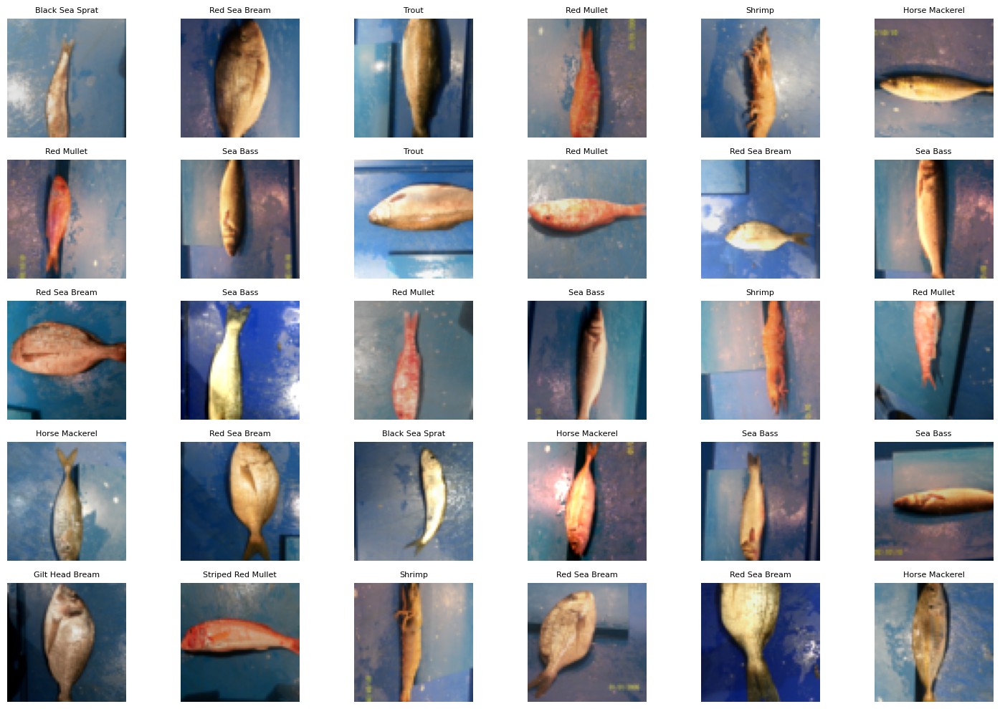

In [ ]:
# --- Visualization Helper ---
# Precompute broadcast-compatible normalization tensors
mean_t = torch.tensor(mean).view(1, 3, 1, 1)  # Shape: (1, C, 1, 1) for batch broadcasting
std_t = torch.tensor(std).view(1, 3, 1, 1)


def unnormalize(x):
    """
    Reverses normalization for visualization.
    Applies inverse transform: x_original = x_normalized * std + mean
    """
    return (x * std_t) + mean_t


# --- Visualize Sample Batch ---
x, y = next(iter(train_loader))
x = x[:30]  # Select 30 samples
y = y[:30]

# Reverse normalization and clamp to valid display range
x_vis = unnormalize(x).clamp(0, 1)

plt.figure(figsize=(15, 10))
for i in range(30):
    plt.subplot(5, 6, i + 1)
    img = x_vis[i].permute(1, 2, 0) # CHW → HWC
    plt.imshow(img)
    plt.title(train_full_pre.classes[int(y[i])], fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Utility Functions & Training Pipeline

This module implements a complete pipeline for training, evaluating, and analyzing deep learning models in PyTorch. The code is structured to ensure **reproducibility**, **efficiency**, and **modularity**.

### Key Utility Functions

| Function | Technical Description | Educational Purpose |
| :--- | :--- | :--- |
| **`calculate_accuracy`** | Computes the top-1 accuracy by comparing the index of the max logit (`argmax`) with the ground truth label. | Fundamental metric to assess classification performance. |
| **`set_all_seeds`** | Sets Random Number Generators (RNG) for Python (`random`), NumPy (`np.random`), and PyTorch (`torch.manual_seed` for CPU & CUDA). | Ensures **deterministic results**: re-running the code will yield the exact same initialization and data shuffling, which is crucial for debugging and scientific validity. |

In [ ]:
def calculate_accuracy(y_pred, y):
    """
    Computes classification accuracy from model predictions.
    """
    # Get predicted class, i.e., index of max logit
    top_pred = y_pred.argmax(1, keepdim=True)

    # Compare predictions to ground truth, sum correct
    correct = top_pred.eq(y.view_as(top_pred)).sum()

    # Normalize by batch size for accuracy percentage
    acc = correct.float() / y.shape[0]
    return acc

def set_all_seeds(seed: int):
    """Set RNG seeds for Python, NumPy, and PyTorch (CPU + CUDA) for repeatability."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

### Core Training & Evaluation Loops

These functions handle the lifecycle of a single epoch. It is critical to distinguish between training and inference because layers like **Dropout** and **BatchNorm** behave differently.

| Phase | Function | Model Mode | Gradient Handling | Operational Steps |
| :--- | :--- | :--- | :--- | :--- |
| **Training** | `train()` | `model.train()` | **Enabled** (`backward()`) | 1. Forward Pass<br>2. Compute Loss<br>3. **Zero Gradients** (`optimizer.zero_grad()`)<br>4. Backpropagation<br>5. Update Weights (`optimizer.step()`) |
| **Evaluation** | `evaluate()` | `model.eval()` | **Disabled** (`torch.no_grad()`) | Performs only the Forward Pass to compute metrics on unseen data. Disabling gradients reduces VRAM usage and speeds up computation. |

In [ ]:
def train(model, iterator, optimizer, criterion, device):
    """
    Executes one training epoch over the provided data iterator. 

    Performs forward pass, loss computation, backpropagation, and
    parameter updates for each batch. Returns average loss and
    accuracy across all batches.
    """
    epoch_loss = 0
    epoch_acc = 0


    # Set model to training mode: activates Dropout and BatchNormalization layers when present
    # il dropout disattiva alcuni neuroni a caso per evitare overfitting (restano spenti sia in forward phase che in backpropagation, la maschera che spegne a caso i neuroni viene rigenerata a ogni batch)
    # batchnorm usa le statistiche del batch corrente per normalizzare l'output della convoluzione, rende più stabile il training
    model.train()
    for (x, y) in tqdm(iterator, desc="Training", leave=False):

        # Transfer batch to compute device (CPU/GPU)
        x = x.to(device)
        y = y.to(device)

        # Clear gradients from previous iteration (PyTorch accumulates by default)
        optimizer.zero_grad()

        # Forward pass: extract logits (predictions) from the model's primary output
        y_pred, _ = model(x)

        # Calculate Cross-Entropy loss and batch accuracy
        loss = criterion(y_pred, y)
        acc = calculate_accuracy(y_pred, y)

        # Backward pass: compute gradients of the loss with respect to model parameters
        loss.backward()

        # Optimization step: update model weights based on computed gradients
        optimizer.step()

        # Accumulate metrics (.item() extracts scalar for Python operations)
        epoch_loss += loss.item()
        epoch_acc += acc.item()

    # Return epoch averages
    return epoch_loss / len(iterator), epoch_acc / len(iterator)

def evaluate(model, iterator, criterion, device):
    """
    Evaluates model performance on the provided data iterator.

    Runs inference without gradient computation and returns average
    loss and accuracy across all batches.
    """
    epoch_loss = 0
    epoch_acc = 0

    # Set model to evaluation mode: freezes BatchNorm statistics and disables Dropout
    # importante se la validational loss è più bassa della training loss è perché il dropout è disabilitato 
    model.eval()

    # Disable gradient computation for inference (saves memory and compute)
    with torch.no_grad():
        for (x, y) in tqdm(iterator, desc="Evaluating", leave=False):
            x = x.to(device)
            y = y.to(device)

            # Forward pass only (no backward needed for evaluation)
            y_pred, _ = model(x)
            loss = criterion(y_pred, y)
            acc = calculate_accuracy(y_pred, y)

            epoch_loss += loss.item()
            epoch_acc += acc.item()

    return epoch_loss / len(iterator), epoch_acc / len(iterator)

In [ ]:
# conta i parametri del modello per avere un'idea della complessità e fare una fair comparison tra modelli
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

### Inference & Analysis Tools

These functions are critical for extracting data from the trained model to perform post-hoc analysis. They bridge the gap between PyTorch tensors (GPU) and analysis libraries like Scikit-learn (CPU).

| Function | Operational Logic | Output Data | Primary Use Case |
| :--- | :--- | :--- | :--- |
| **`get_predictions()`** | Performs a full forward pass on the dataset and applies **Softmax** to normalize logits into probabilities. | `(images, labels, probs)` on **CPU**. | Calculating quantitative metrics (Accuracy, F1-Score) and generating Confusion Matrices. |
| **`get_representations()`** | Intercepts the signal at the **penultimate layer** (before the final classification head) to extract learned features. | `(features, labels)` on **CPU**. | Dimensionality reduction (PCA/t-SNE) to visualize how the model "clusters" similar images in the feature space. |

In [ ]:
def get_predictions(model, iterator, device):
    """
    Extracts predictions and probabilities from a trained model.

    Runs inference over the entire dataset and returns:
    - images: input tensors (CPU)
    - labels: ground truth labels (CPU)
    - probs: predicted class probabilities (CPU)
    """
    model.eval()

    images = []
    labels = []
    probs = []

    with torch.no_grad():
        for (x, y) in tqdm(iterator, desc="Predicting", leave=False):
            x = x.to(device)

            # Get raw logits from model
            y_pred, _ = model(x)

            # Convert logits to probabilities via softmax
            y_prob = F.softmax(y_pred, dim=-1)

            # Move to CPU for sklearn compatibility and memory efficiency
            images.append(x.cpu())
            labels.append(y.cpu())
            probs.append(y_prob.cpu())

    # Concatenate all batches into single tensors
    images = torch.cat(images, dim=0)
    labels = torch.cat(labels, dim=0)
    probs = torch.cat(probs, dim=0)

    return images, labels, probs

def get_representations(model, iterator, device):
    """
    Extracts feature representations from a trained model.

    Collects the hidden features (penultimate layer) for dimensionality
    reduction and visualization purposes.
    """
    model.eval()

    outputs = []
    labels = []

    with torch.no_grad():
        for (x, y) in tqdm(iterator, desc="Extracting features", leave=False):
            x = x.to(device)

            # Model returns (logits, hidden_features); we use hidden features for visualization
            # le hidden features sono l'output dell'ultimo layer prima della classificazione
            _, h = model(x)
            outputs.append(h.cpu())
            labels.append(y)

    # Stack all representations for dimensionality reduction
    outputs = torch.cat(outputs, dim=0)
    labels = torch.cat(labels, dim=0)

    return outputs, labels

### Visualization (Dimensionality Reduction)

To understand what the model has learned, we project the high-dimensional feature vectors into a 2D space.

| Component | Method Type | Technical Description | Visual Insight Goal |
| :--- | :--- | :--- | :--- |
| **`get_pca`** | **Linear** | Principal Component Analysis. Preserves global variance. | Checks if classes are **linearly separable**. Good for a "big picture" view of the data distribution. |
| **`get_tsne`** | **Non-linear** | t-Distributed Stochastic Neighbor Embedding. Preserves local neighborhoods. | Reveals complex **clusters and manifolds**. Shows if the model groups similar classes together (e.g., distinct islands for "cats" vs "dogs"). |
| **`plot_representations`** | **Plotting** | Generates a 2D scatter plot color-coded by ground truth class. | Visual verification of class boundaries. Ideally, points of the same color should form tight, isolated groups. |

In [ ]:
def get_pca(data, n_components=2):
    """
    Applies Principal Component Analysis for dimensionality reduction.

    Projects high-dimensional data onto principal axes that capture
    maximum variance. Useful for visualizing learned representations.
    """
    pca = decomposition.PCA()

    # Project to 2D for visualizati
    pca.n_components = n_components
    pca_data = pca.fit_transform(data)
    return pca_data

def plot_representations(data, labels, classes, n_images=None):
    """
    Creates a 2D scatter plot of learned representations.

    Points are colored by class label to visualize cluster separation.
    Good separation indicates the model has learned discriminative features.
    """
    if n_images is not None:
        data = data[:n_images]
        labels = labels[:n_images]

    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111)

    # Use tab10 colormap for up to 10 distinct classes
    scatter = ax.scatter(data[:, 0], data[:, 1], c=labels, cmap='tab10')

    # Create legend with class names
    handles, _ = scatter.legend_elements()
    ax.legend(handles=handles, labels=classes)
    plt.show()

def get_tsne(data, n_components=2, n_images=None):
    """
    Applies t-SNE for nonlinear dimensionality reduction.

    t-SNE preserves local neighborhood structure better than PCA,
    often revealing cluster structure in complex high-dimensional data.
    Computationally expensive: O(n²), hence the n_images limit.
    """
    if n_images is not None:
        data = data[:n_images]

    # random_state ensures reproducible embedding
    tsne = manifold.TSNE(n_components=n_components, random_state=0)
    tsne_data = tsne.fit_transform(data)
    return tsne_data

# Multi-Layer Perceptron (MLP)

The Multi-Layer Perceptron represents the foundational architecture of deep learning, consisting of fully-connected layers where every neuron connects to every neuron in adjacent layers.

**Why MLP as Baseline?**

While suboptimal for image classification, MLPs provide a valuable performance floor that CNN architectures must exceed, illustrate why spatial inductive biases matter for visual tasks, and help isolate data pipeline issues through their architectural simplicity.

**Fundamental Limitation:** MLPs process images by flattening them into 1D vectors ($64 \times 64 \times 3 = 12{,}288$ dimensions), destroying spatial structure. Adjacent pixels are treated identically to distant pixels, with no translation invariance.

## MLP Architecture Design

For a $64 \times 64 \times 3$ input image, the first layer flattens the input to $12,288$ features.
The network follows a funnel structure:
1.  **Input -> Hidden 1**: Maps $12,288 \to 250$ features ($~3.07M$ parameters).
2.  **Hidden 1 -> Hidden 2**: Maps $250 \to 100$ features, adding depth and non-linearity.
3.  **Hidden 2 -> Output**: Maps $100 \to N_{classes}$.

**Regularization Strategy:**
- **Dropout ($p=0.3$)**: Applied before the final classification layer to reduce overfitting.

In [ ]:
# --- MLP Architecture Definition ---
OUTPUT_DIM = len(train_full_pre.classes)
print("OUTPUT_DIM:", OUTPUT_DIM, "| Classes:", train_full_pre.classes)


class MLP(nn.Module):
    """
    Multi-Layer Perceptron for image classification.

    Processes flattened image tensors through fully-connected layers
    with ReLU activations and dropout regularization.
    """

    def __init__(self, output_dim, dropout=0.3):
        """
        Initializes the MLP architecture.
        """
        super().__init__()
        # First Hidden Layer (Input -> 250)
        self.fc1 = nn.LazyLinear(250)
        # Second Hidden Layer (250 -> 100)
        self.fc2 = nn.Linear(250, 100)
        # Output Layer (100 -> num_classes)
        self.fc3 = nn.Linear(100, output_dim)

        # Regularization: randomly zero activations
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        """
        Forward pass through the MLP.
        """
        # Flatten spatial dimensions: (B, C, H, W) → (B, C*H*W)
        x = x.view(x.size(0), -1)

        # Hidden layers with ReLU
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))

        # Dropout before final layer (consistent with MiniVGG style)
        h2 = self.drop(h2)

        # Output layer (raw logits)
        logits = self.fc3(h2)

        # Return both logits and penultimate features (for visualization)
        return logits, h2


def count_parameters(model):
    """
    Counts trainable parameters in a model.
    """
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Instantiate and verify architecture
model = MLP(OUTPUT_DIM).to(device)

# Forward pass to trigger LazyLinear initialization
x, y = next(iter(train_loader))
x, y = x.to(device), y.to(device)
logits, features = model(x)

print("Input shape:", x.shape)
print("Logits shape:", logits.shape)
print("Features shape:", features.shape)
print("Predictions (first 10):", logits.argmax(dim=1)[:10].detach().cpu().tolist())
print("Ground truth (first 10):", y[:10].detach().cpu().tolist())
print(f"Total trainable parameters: {count_parameters(model):,}")

OUTPUT_DIM: 9 | Classes: ['Black Sea Sprat', 'Gilt Head Bream', 'Horse Mackerel', 'Red Mullet', 'Red Sea Bream', 'Sea Bass', 'Shrimp', 'Striped Red Mullet', 'Trout']
Input shape: torch.Size([128, 3, 64, 64])
Logits shape: torch.Size([128, 9])
Features shape: torch.Size([128, 100])
Predictions (first 10): [0, 5, 1, 6, 6, 1, 6, 8, 8, 6]
Ground truth (first 10): [6, 4, 6, 4, 1, 0, 1, 1, 7, 2]
Total trainable parameters: 3,098,259


## Optimizer and Loss Function

**Adam Optimizer** combines the benefits of Momentum (gradient history smoothing) and RMSProp (per-parameter learning rate adaptation), making it robust to hyperparameter choices.

**Cross-Entropy Loss** for multi-class classification:

$$\mathcal{L} = -\sum_{c=1}^{C} y_c \log(\hat{y}_c)$$

where $y_c$ is the one-hot ground truth and $\hat{y}_c$ is the predicted probability. This loss heavily penalizes confident wrong predictions.

In [ ]:
# --- Configure Optimizer and Loss ---

optimizer = optim.Adam(model.parameters())

# CrossEntropyLoss: Loss function for multi-class classification.
criterion = nn.CrossEntropyLoss()

# Move model and loss to compute device
model = model.to(device)
criterion = criterion.to(device)

## Device Verification

Operations between tensors on different devices (CPU vs. GPU) raise runtime errors. A verification check prevents cryptic error messages during training.

In [ ]:
print("Model parameter device:", next(model.parameters()).device)

xb, yb = next(iter(train_loader))
xb, yb = xb.to(device), yb.to(device)

print("Input tensor device:", xb.device)
print("Label tensor device:", yb.device)

Model parameter device: cuda:0
Input tensor device: cuda:0
Label tensor device: cuda:0


## Hyperparameter Search

Neural network performance depends critically on hyperparameters (learning rate, regularization strength) that cannot be learned via gradient descent.

**Successive Halving Strategy:**

1. **Stage 1 (Screening)**: Evaluate many configurations with minimal resources (few epochs)
2. **Stage 2 (Refinement)**: Allocate more epochs to promising candidates

| Hyperparameter | Range | Rationale |
|----------------|-------|-----------|
| Learning Rate | $10^{-2}$ to $3 \times 10^{-5}$ | Log-uniform sampling covers orders of magnitude |
| Weight Decay | $0$ to $10^{-3}$ | Weight decay regularization strength |
| Dropout | $0$ to $0.5$ | Activation regularization |

In [ ]:
# --- Hyperparameter Search Configuration ---

def epoch_time(start_time, end_time):
    """
    Calculates elapsed time in minutes and seconds.
    """
    elapsed_time = end_time - start_time
    elapsed_mins = int(elapsed_time / 60)
    elapsed_secs = int(elapsed_time - (elapsed_mins * 60))
    return elapsed_mins, elapsed_secs

# run di una configurazione di iperparametri con early stopping controllato in due modi: max_epochs e patience
def run_one_cfg(cfg, max_epochs, patience, seed):
    """
    Trains a single MLP configuration with early stopping.
    """
    # Ensure reproducibility across configurations
    set_all_seeds(seed)

    # Build model with current hyperparameters
    model = MLP(OUTPUT_DIM, dropout=cfg["dropout"]).to(device)

    # Initialize AdamW optimizer
    optimizer = optim.AdamW(
        model.parameters(),
        lr=cfg["lr"],
        weight_decay=cfg["weight_decay"]
    )
    criterion = nn.CrossEntropyLoss().to(device)

    best_val_loss = float("inf")
    best_state = None

    # Counter for epochs without improvement
    bad = 0

    for epoch in range(max_epochs):
        train_loss, train_acc = train(model, train_loader, optimizer, criterion, device)
        # viene utilizzata la validational loss come metrica per determinare il modello migliore
        # nell evaluate il dropout è disabilitato
        val_loss, val_acc = evaluate(model, val_loader, criterion, device)

        # Checkpoint Strategy: Save only if validation loss improves
        if val_loss < best_val_loss:
            best_val_loss = val_loss

            # Use deepcopy to store the actual weight
            # best state è lo stato del modello, pesi e bias, con la migliore performance sulla validation
            best_state = copy.deepcopy(model.state_dict())
            bad = 0
        else:
            bad += 1

            # Early Stopping Trigger
            if bad >= patience:
                break

    # Cleanup to free GPU memory before next configuration
    del model
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return best_val_loss, best_state


# Time budget (prevents runaway experiments)
TIME_BUDGET_SEC = 1000 * 60
t0 = time.time()

# --- Search Space Definition ---
# Log-spaced learning rates cover 3 orders of magnitude
LR_CANDIDATES = [1e-2, 3e-3, 1e-3, 3e-4, 1e-4, 3e-5]
# Weight decay: from none to strong L2 regularization
WD_CANDIDATES = [0.0, 1e-6, 1e-5, 1e-4, 1e-3]
# Dropout: from none to aggressive regularization
DROPOUT_CANDIDATES = [0.0, 0.1, 0.3, 0.5]


def sample_cfg(rng):
    """
    Randomly samples a hyperparameter configuration.
    """
    return {
        "lr": float(rng.choice(LR_CANDIDATES)),
        "weight_decay": float(rng.choice(WD_CANDIDATES)),
        "dropout": float(rng.choice(DROPOUT_CANDIDATES)),
    }


# --- Stage 1 Configuration: Quick Screening ---
SEED_STAGE1 = 1234
# Number of random configurations to try
N_TRIALS_STAGE1 = 24
# Few epochs to quickly identify poor configs
EPOCHS_STAGE1 = 2
# Minimal patience for fast elimination
PATIENCE_STAGE1 = 1

# --- Stage 2 Configuration: Detailed Evaluation ---
SEED_STAGE2 = 1234
# Number of survivors from Stage 1
TOPK = 6
# More epochs for reliable comparison
EPOCHS_STAGE2 = 15
# More patience to avoid premature stopping
PATIENCE_STAGE2 = 3

# Reproducible random sampling
rng = np.random.default_rng(1234)

# --- Execute Stage 1: Screening ---
stage1 = []
print(f"Stage 1: {N_TRIALS_STAGE1} trials x {EPOCHS_STAGE1} epochs (max)")

for i in tqdm(range(1, N_TRIALS_STAGE1 + 1), desc="Stage 1"):
    # Respect time budget to prevent runaway experiments
    if time.time() - t0 > TIME_BUDGET_SEC:
        print("Time budget reached during Stage 1.")
        break

    cfg = sample_cfg(rng)
    val_loss, _ = run_one_cfg(cfg, EPOCHS_STAGE1, PATIENCE_STAGE1, SEED_STAGE1)
    stage1.append((val_loss, cfg))
    # printa i risultati di ogni configurazione testata
    print(f"[S1 {i:02}/{N_TRIALS_STAGE1}] val_loss={val_loss:.4f} cfg={cfg}")

# Sort by validation loss (ascending) to identify best performers
stage1_sorted = sorted(stage1, key=lambda x: x[0])
survivors = [cfg for (_, cfg) in stage1_sorted[:min(TOPK, len(stage1_sorted))]]

# mostra le migliori configurazioni di stage 1
print("\nStage 1 Top Configurations:")
for j, (vl, cfg) in enumerate(stage1_sorted[:min(TOPK, len(stage1_sorted))], start=1):
    print(f"{j}) val_loss={vl:.4f} cfg={cfg}")

# --- Execute Stage 2: Refinement on Survivors ---
best = {"val_loss": float("inf"), "cfg": None, "state_dict": None}
print(f"\nStage 2: {len(survivors)} configs x {EPOCHS_STAGE2} epochs (max) with early stopping")

for k, cfg in enumerate(survivors, start=1):
    if time.time() - t0 > TIME_BUDGET_SEC:
        print("Time budget reached during Stage 2.")
        break

    val_loss, state = run_one_cfg(cfg, EPOCHS_STAGE2, PATIENCE_STAGE2, SEED_STAGE2)
    # printa i risultati di ogni configurazione (survivors di stage 1) allenata meglio 
    print(f"[S2 {k:02}/{len(survivors)}] val_loss={val_loss:.4f} cfg={cfg}")

    # Track global best across all Stage 2 trials
    if val_loss < best["val_loss"]:
        best["val_loss"] = val_loss
        best["cfg"] = cfg
        best["state_dict"] = state

print("\nBest Configuration:", best["cfg"], "| val_loss:", best["val_loss"])
print("Total search time (min):", (time.time() - t0) / 60)

# --- Save Best Configuration for Later Use ---
torch.save({"cfg": best["cfg"], "state_dict": best["state_dict"]}, "mlp-grid-best.pt")

# --- Restore Best Model ---
model = MLP(OUTPUT_DIM, dropout=best["cfg"]["dropout"]).to(device)
model.load_state_dict(best["state_dict"])
optimizer = optim.AdamW(
    model.parameters(),
    lr=best["cfg"]["lr"],
    weight_decay=best["cfg"]["weight_decay"]
)
criterion = nn.CrossEntropyLoss().to(device)

## MLP Final Training

The **final training** of the MLP model is performed using the **best hyperparameter configuration** obtained from the grid search phase.

### Load Best Configuration

The best configuration is loaded from a saved grid-search checkpoint. Two options are supported:
- a **reference grid checkpoint** for reproducibility,
- a **local grid checkpoint** produced during experimentation.

The checkpoint contains the selected hyperparameters, which are extracted and used to initialize the model and optimizer.

### Reproducibility

Before starting the final training run, all relevant random seeds are reset (Python, NumPy, and PyTorch) to ensure deterministic behavior across runs.

In [ ]:
# --- Load Best Configuration and Final Training ---
USE_REFERENCE_GRID = False # This variable will appear multiple time over the following cells during the usage of the models: if set on TRUE, it uses the reference model downloaded from Drive, if on FALSE it uses the local one.
LOCAL_GRID_PATH = "mlp-grid-best.pt"
grid_path = LOCAL_GRID_PATH

if USE_REFERENCE_GRID:
    grid_path = str(REF_MLP_GRID)

ckpt = torch.load(grid_path, map_location=device)
best_cfg = ckpt["cfg"]
print("Loaded best configuration:", best_cfg)

# Reset seeds to ensure the final training run is deterministic
random.seed(1234)
np.random.seed(1234)
torch.manual_seed(1234)
torch.cuda.manual_seed_all(1234)

# --- Initialize Model from Scratch ---
model = MLP(OUTPUT_DIM, dropout=best_cfg["dropout"]).to(device)
optimizer = optim.AdamW(
    model.parameters(),
    lr=best_cfg["lr"],
    weight_decay=best_cfg["weight_decay"],
)
criterion = nn.CrossEntropyLoss().to(device)

# --- Training Configuration ---
MAX_EPOCHS = 50
PATIENCE = 5

best_valid_loss = float("inf")
best_state = None
bad_epochs = 0

train_losses, val_losses = [], []
train_accs, val_accs = [], []

# --- Training Loop ---
for epoch in trange(MAX_EPOCHS, desc="Training"):
    start_time = time.monotonic()

    # Perform forward/backward pass and evaluation
    train_loss, train_acc = train(model, train_loader, optimizer, criterion, device)
    valid_loss, valid_acc = evaluate(model, val_loader, criterion, device)

    # Log metrics
    train_losses.append(train_loss)
    val_losses.append(valid_loss)
    train_accs.append(train_acc)
    val_accs.append(valid_acc)

    if valid_loss < best_valid_loss:
        best_valid_loss = valid_loss
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, "mlp-model.pt")
        bad_epochs = 0
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1} (no improvement for {PATIENCE} epochs)")
            break

    end_time = time.monotonic()
    epoch_mins, epoch_secs = epoch_time(start_time, end_time)

    print(f"Epoch: {epoch+1:02} | Time: {epoch_mins}m {epoch_secs}s")
    print(f"\tTrain Loss: {train_loss:.3f} | Train Acc: {train_acc*100:.2f}%")
    print(f"\tVal Loss: {valid_loss:.3f} | Val Acc: {valid_acc*100:.2f}%")

print("Training complete. Best val_loss:", best_valid_loss)
model.load_state_dict(best_state)

# --- Plot Learning Curves ---
epochs = range(1, len(train_losses) + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP Training vs Validation Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## MLP Model Evaluation

The trained **MLP** model is evaluated on a **held-out test set** to assess its generalization capability on unseen data. The evaluation follows standard practices in supervised classification and relies on widely adopted performance metrics to provide both **global** and **class-wise** insights into the model’s behavior.

### Evaluation Setup

The evaluation pipeline supports two alternative configurations:

* **Reference model checkpoint**, used to ensure *reproducibility* and fair comparison with previously reported results.
* **Locally trained model checkpoint**, enabling validation of newly trained weights.

### Prediction Generation

Once the model is loaded, predictions are generated on the test set using a dedicated inference function. For each input sample, the model outputs class probabilities, from which the final predicted label is obtained by selecting the class with the highest probability (argmax operation).

This process yields:

* **Ground-truth labels** (`y_true`)
* **Predicted labels** (`y_pred`)
* **Class probability distributions**

### Evaluation Metrics

The model performance is quantified using the following metrics:

* **Accuracy**
  Measures the overall proportion of correctly classified samples. While intuitive, accuracy alone may be misleading in the presence of class imbalance.

* **Precision, Recall, and F1-score (per class)**
  These metrics provide a more fine-grained evaluation:

  * *Precision* quantifies how many predicted samples of a given class are correct.
  * *Recall* measures how many samples of a given class are correctly identified.
  * *F1-score* represents the harmonic mean of precision and recall, balancing the two aspects.

  A complete **classification report** is generated, reporting these metrics for each class along with macro- and weighted-averaged scores.

* **Confusion Matrix**
  The confusion matrix offers a detailed visualization of classification errors by showing how samples from each true class are distributed across predicted classes. This representation is particularly useful for identifying systematic misclassification patterns and class confusions.

### Visualization

The confusion matrix is displayed using a color-coded heatmap, with:

* Rows corresponding to true labels
* Columns corresponding to predicted labels
* Cell values indicating the number of samples

Predicting:   0%|          | 0/2 [00:00<?, ?it/s]

Accuracy: 0.7093023255813954

Classification Report:
                     precision    recall  f1-score   support

   Black Sea Sprat       0.50      0.40      0.44        10
   Gilt Head Bream       0.50      0.70      0.58        10
    Horse Mackerel       0.62      0.50      0.56        10
        Red Mullet       0.88      0.70      0.78        10
     Red Sea Bream       0.69      0.90      0.78        10
          Sea Bass       0.83      1.00      0.91        10
            Shrimp       0.91      1.00      0.95        10
Striped Red Mullet       0.71      0.50      0.59        10
             Trout       0.80      0.67      0.73         6

          accuracy                           0.71        86
         macro avg       0.72      0.71      0.70        86
      weighted avg       0.71      0.71      0.70        86



<Figure size 1000x1000 with 0 Axes>

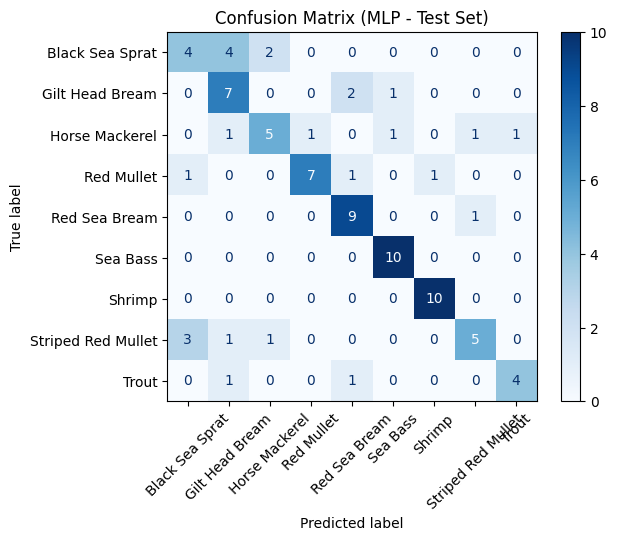

In [ ]:
# --- Load Best Configuration ---
USE_REFERENCE_MODEL = True
LOCAL_CKPT_PATH = "mlp-model.pt"
ckpt_path = LOCAL_CKPT_PATH

if USE_REFERENCE_MODEL:
    ckpt_path = str(REF_MLP_MODEL)

# Load best configuration to get dropout value
if USE_REFERENCE_MODEL and REF_MLP_GRID.exists():
    grid_ckpt = torch.load(REF_MLP_GRID, map_location=device)
    dropout_val = grid_ckpt["cfg"]["dropout"]
else:
    # Default if grid checkpoint not available
    dropout_val = 0.5

model = MLP(OUTPUT_DIM, dropout=dropout_val).to(device)
model.load_state_dict(torch.load(ckpt_path, map_location=device))

# --- Generate Predictions ---
images, labels, probs = get_predictions(model, test_loader, device)

y_true = labels.numpy()
y_pred = probs.argmax(dim=1).numpy()

# --- Compute Metrics ---
cm = confusion_matrix(y_true, y_pred)
print("Accuracy:", accuracy_score(y_true, y_pred))
print("\nClassification Report:\n", classification_report(y_true, y_pred, target_names=train_full_pre.classes))

# --- Plot Confusion Matrix ---
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=train_full_pre.classes)
plt.figure(figsize=(10, 10))
disp.plot(cmap="Blues", values_format="d", xticks_rotation=45)
plt.title("Confusion Matrix (MLP - Test Set)")
plt.show()

# VGG Network (Mini-VGG)

VGGNet (Simonyan & Zisserman, 2014) demonstrated that network depth is crucial for visual representations. Unlike predecessors using large filters ($11 \times 11$, $7 \times 7$), VGG achieved state-of-the-art ImageNet performance with only **$3 \times 3$ convolutions**.

**Key Architectural Insights:**

- **Small filters, more layers**: Two $3 \times 3$ convolutions have the same receptive field as one $5 \times 5$, but with more non-linearities and fewer parameters
- **Consistent structure**: Repeating Conv-ReLU-Conv-ReLU-Pool blocks
- **Feature map progression**: Channels double after each pooling ($64 \to 128 \to 256 \to 512$)

**Mini-VGG Adaptation:** The original VGG-16 has ~138M parameters—too large for our dataset. We implement a scaled-down variant with reduced channel counts and optional batch normalization.

In [ ]:
# --- Mini-VGG Architecture Definition ---

OUTPUT_DIM = len(train_full_pre.classes)
print("OUTPUT_DIM:", OUTPUT_DIM, "| Classes:", train_full_pre.classes)

# --- VGG Configuration Tables ---

# Each config defines layer structure: integers = conv output channels, 'M' = MaxPool
# Numbers are halved from original VGG (64->32, 128->64, etc.) to reduce overfitting

VGG_CFGS = {
    # VGG-11: 8 conv layers - simplest variant
    "vgg11": [32, "M", 64, "M", 128, 128, "M", 256, 256, "M", 256, 256, "M"],

    # VGG-13: 10 conv layers - adds one conv per block
    "vgg13": [32, 32, "M", 64, 64, "M", 128, 128, "M", 256, 256, "M", 256, 256, "M"],

    # VGG-16: 13 conv layers - three convs in later blocks
    "vgg16": [32, 32, "M", 64, 64, "M", 128, 128, 128, "M", 256, 256, 256, "M", 256, 256, 256, "M"],

    # VGG-19: 16 conv layers - deepest variant
    "vgg19": [32, 32, "M", 64, 64, "M", 128, 128, 128, 128, "M", 256, 256, 256, 256, "M", 256, 256, 256, 256, "M"],
}

# Un canale è una feature in pratica, ovvero un pattern riconosciuto dalla convoluzione, un kernle = un pattern = un canale
# Il pooling riduce la dimensione spaziale dell'immagine, mantenendo invariato il numero di canali

# costruisce l'architettura delle feature extraction layers di VGG
def make_vgg_features(cfg, batch_norm=False):
    """
    Constructs the feature extraction layers for VGG architecture.

    Builds a sequence of convolutional and pooling layers based on
    the provided configuration list. Each integer specifies the output
    channels for a Conv2d layer, and 'M' indicates MaxPool2d.
    """
    layers = []
    in_channels = 3  # RGB input, perchè ho 3 canali

    for v in cfg:
        if v == "M":
            # MaxPool halves spatial dimensions, provides translation invariance
            layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
        else:
            # 3x3 conv with padding=1 preserves spatial dimensions
            conv = nn.Conv2d(in_channels, v, kernel_size=3, padding=1)

            if batch_norm:
                # BatchNorm normalizes activations, enabling higher learning rates
                layers += [conv, nn.BatchNorm2d(v), nn.ReLU(inplace=True)] # sigma + funzione di normalizzazione
            else:
                layers += [conv, nn.ReLU(inplace=True)]

            in_channels = v  # Output channels become next layer's input

    return nn.Sequential(*layers)


class MiniVGG(nn.Module):
    """
    Mini-VGG architecture for image classification.

    A lightweight variant of VGGNet with reduced channel counts
    and a compact classifier head. Supports optional batch
    normalization and configurable dropout.
    """

    def __init__(self, name, output_dim, batch_norm=False, dropout=0.5):
        """
        Initializes the MiniVGG architecture.
        """
        super().__init__()

        name = name.lower()
        if name not in VGG_CFGS:
            raise ValueError(f"Unknown VGG variant '{name}'. Choose from: {list(VGG_CFGS.keys())}")

        # Convolutional feature extractor
        self.features = make_vgg_features(VGG_CFGS[name], batch_norm=batch_norm)

        # Global average pooling: reduces any spatial size to 1x1
        # fa in modo che alla fine ogni filtro contenga solo una singola informazione riassuntiva indipendentemente dalla dimensione spaziale dell'input
        # si perde l'informazione su dove si trova si trova il pattern, si mantiene solo l'informazione che il pattern è presente o meno
        # serve per ridurre la dimensionalità di ingresso alla classification head
        # in questo modo si da al classificare un input compatto su tutte le feature estratte dalle convoluzioni
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))

        # Determine quanti input features riceve il classificatore in base all'architettura scelta
        last_channels = [v for v in VGG_CFGS[name] if isinstance(v, int)][-1]
        in_dim = last_channels * 1 * 1

        # Compact classifier head (original VGG had 4096-4096-1000; we use 256-output_dim)
        # layer ulteriore che funge da classificatore vero e proprio alla fine della rete e che riceve in input le feature estratte dalle convoluzioni 
        hidden_dim = 256
        self.classifier = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.Linear(hidden_dim, output_dim),
        )

    def forward(self, x):
        """
        Forward pass through MiniVGG.
        """
        # Extract hierarchical features through conv layers
        x = self.features(x)

        # Global average pooling: (B, C, H, W) -> (B, C, 1, 1)
        # fa in modo che alla fine ogni filtro contenga solo una singola informazione riassuntiva indipendentemente dalla dimensione spaziale dell'input
        x = self.avgpool(x)

        # Flatten for classifier: (B, C, 1, 1) -> (B, C)
        # i moduli classifier si aspettano un input monodimensionale per ogni esempio, quindi devo ridurre il tensore a array
        h = torch.flatten(x, 1)

        # Classification layer 
        logits = self.classifier(h)

        # Return both logits and penultimate features (for visualization)
        return logits, h


# --- Instantiate and Verify Architecture ---

VGG_NAME = "vgg11"   # Simplest variant
USE_BN = False       # BatchNorm will be tuned in hyperparameter search
DROPOUT = 0.5        # Default dropout rate

model = MiniVGG(VGG_NAME, OUTPUT_DIM, batch_norm=USE_BN, dropout=DROPOUT).to(device)

# Forward pass to verify model
x, y = next(iter(train_loader))
x, y = x.to(device), y.to(device)
logits, features = model(x)

print("Input shape:", x.shape)
print("Logits shape:", logits.shape)
print("Features shape:", features.shape)
print("Predictions (first 10):", logits.argmax(dim=1)[:10].detach().cpu().tolist())
print("Ground truth (first 10):", y[:10].detach().cpu().tolist())
print(f"Total trainable parameters: {count_parameters(model):,}")

OUTPUT_DIM: 9 | Classes: ['Black Sea Sprat', 'Gilt Head Bream', 'Horse Mackerel', 'Red Mullet', 'Red Sea Bream', 'Sea Bass', 'Shrimp', 'Striped Red Mullet', 'Trout']
Input shape: torch.Size([128, 3, 64, 64])
Logits shape: torch.Size([128, 9])
Features shape: torch.Size([128, 256])
Predictions (first 10): [2, 2, 2, 4, 2, 2, 2, 4, 4, 2]
Ground truth (first 10): [0, 2, 1, 1, 4, 5, 5, 8, 7, 3]
Total trainable parameters: 2,374,345


## VGG Hyperparameter Search

Two-stage successive halving efficiently explores a larger hyperparameter space:

1. **Stage 1**: Screen 24 random configurations with 2 epochs each
2. **Stage 2**: Train top-6 survivors for 5 epochs with early stopping

| Hyperparameter | Range | Rationale |
|----------------|-------|-----------|
| Learning Rate | $[10^{-4}, 3 \times 10^{-3}]$ | Log-uniform exploration |
| Weight Decay | $[0, 10^{-3}]$ | Uniform from none to moderate |
| Dropout | $[0, 0.5]$ | Classifier regularization |
| Architecture | vgg11 | Depth vs. parameter trade-off |
| Batch Norm | True/False | Training stability vs. simplicity |

In [ ]:
# --- Hyperparameter Search Configuration ---
def epoch_time(start_time, end_time):
    """
    Calculates elapsed time in minutes and seconds.
    """
    elapsed_time = end_time - start_time
    elapsed_mins = int(elapsed_time / 60)
    elapsed_secs = int(elapsed_time - (elapsed_mins * 60))
    return elapsed_mins, elapsed_secs

def run_one_cfg(cfg, max_epochs, patience, seed):
    """
    Trains a single VGG configuration with early stopping.

    Performs training with specified hyperparameters and returns
    the best validation loss achieved along with model state dict.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # Build model with sampled configuration
    model = MiniVGG(
        name=cfg["vgg_name"],
        output_dim=OUTPUT_DIM,
        batch_norm=cfg["batch_norm"],
        dropout=cfg["dropout"],
    ).to(device)

    # AdamW separates weight decay from gradient-based updates
    optimizer = optim.AdamW(
        model.parameters(),
        lr=cfg["lr"],
        weight_decay=cfg["weight_decay"]
    )
    criterion = nn.CrossEntropyLoss().to(device)

    best_val_loss = float("inf")
    best_state = None
    bad = 0  # Epochs since last improvement

    for epoch in range(max_epochs):
        train_loss, train_acc = train(model, train_loader, optimizer, criterion, device)
        val_loss, val_acc = evaluate(model, val_loader, criterion, device)

        # Checkpoint Strategy: Save only if validation loss improves
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            bad = 0
        else:
            bad += 1
            # Early Stopping Trigger
            if bad >= patience:
                break

    # Cleanup to free GPU memory before next configuration
    if optimizer is not None:
        del optimizer
    if criterion is not None:
        del criterion
    if model is not None:
        del model
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()

    return best_val_loss, best_state


# Time budget and search space
TIME_BUDGET_SEC = 1000 * 60
t0 = time.time()

# --- Search Space Definition ---
# Log-spaced learning rates cover 3 orders of magnitude
LR_CANDIDATES = [1e-2, 3e-3, 1e-3, 3e-4, 1e-4, 3e-5]

# Weight decay: from none to moderate regularization
# Il weight decay è una regolarizzazione che penalizza pesi grandi,
# spingendo il modello a usare soluzioni più semplici e stabili.
WD_CANDIDATES = [0.0, 1e-6, 1e-5, 1e-4, 1e-3]

# Dropout: from none to heavy regularization
DROPOUT_CANDIDATES = [0.0, 0.1, 0.3, 0.5]

# Architecture variants: vgg11 is fastest to train
VGG_NAME_CANDIDATES = ["vgg11"]

# Batch normalization: can dramatically improve training
BN_CANDIDATES = [False, True]


def sample_cfg(rng):
    """
    Randomly samples a VGG hyperparameter configuration.
    """
    return {
        "lr": float(rng.choice(LR_CANDIDATES)),
        "weight_decay": float(rng.choice(WD_CANDIDATES)),
        "dropout": float(rng.choice(DROPOUT_CANDIDATES)),
        "vgg_name": str(rng.choice(VGG_NAME_CANDIDATES)),
        "batch_norm": bool(rng.choice(BN_CANDIDATES)),
    }

# --- Stage 1 Configuration: Quick Screening ---

SEED_STAGE1 = 1234
N_TRIALS_STAGE1 = 24    # Number of random configurations
EPOCHS_STAGE1 = 2       # Few epochs for quick elimination
PATIENCE_STAGE1 = 1     # Minimal patience

# --- Stage 2 Configuration: Extended Training ---
SEED_STAGE2 = 1234
TOPK = 6                # Keep top-K from stage 1
EPOCHS_STAGE2 = 15      # More epochs for convergence
PATIENCE_STAGE2 = 3     # Standard patience

# Reproducible random sampling
rng = np.random.default_rng(1234)

# --- Execute Stage 1: Screening ---

stage1 = []
print(f"Stage 1: {N_TRIALS_STAGE1} trials x {EPOCHS_STAGE1} epochs (max)")

for i in tqdm(range(1, N_TRIALS_STAGE1 + 1), desc="Stage 1"):
    # Respect time budget to prevent runaway experiments
    if time.time() - t0 > TIME_BUDGET_SEC:
        print("Time budget reached during Stage 1.")
        break

    cfg = sample_cfg(rng)
    val_loss, _ = run_one_cfg(cfg, EPOCHS_STAGE1, PATIENCE_STAGE1, SEED_STAGE1)
    stage1.append((val_loss, cfg))
    print(f"[S1 {i:02}/{N_TRIALS_STAGE1}] val_loss={val_loss:.4f} cfg={cfg}")

# Sort by validation loss (ascending) to identify best performers
stage1_sorted = sorted(stage1, key=lambda x: x[0])
survivors = [cfg for (_, cfg) in stage1_sorted[:min(TOPK, len(stage1_sorted))]]

print("\nStage 1 Top Configurations:")
for j, (vl, cfg) in enumerate(stage1_sorted[:min(TOPK, len(stage1_sorted))], start=1):
    print(f"{j}) val_loss={vl:.4f} cfg={cfg}")

# --- Execute Stage 2: Refinement on Survivors ---
best = {"val_loss": float("inf"), "cfg": None, "state_dict": None}
print(f"\nStage 2: {len(survivors)} configs x {EPOCHS_STAGE2} epochs (max) with early stopping")

for k, cfg in enumerate(survivors, start=1):
    if time.time() - t0 > TIME_BUDGET_SEC:
        print("Time budget reached during Stage 2.")
        break

    val_loss, state = run_one_cfg(cfg, EPOCHS_STAGE2, PATIENCE_STAGE2, SEED_STAGE2)
    print(f"[S2 {k:02}/{len(survivors)}] val_loss={val_loss:.4f} cfg={cfg}")

    # Track global best across all Stage 2 trials
    if val_loss < best["val_loss"]:
        best["val_loss"] = val_loss
        best["cfg"] = cfg
        best["state_dict"] = state

print("\nBest Configuration:", best["cfg"], "| val_loss:", best["val_loss"])

# --- Restore Best Model ---
model = MiniVGG(
    name=best["cfg"]["vgg_name"],
    output_dim=OUTPUT_DIM,
    batch_norm=best["cfg"]["batch_norm"],
    dropout=best["cfg"]["dropout"],
).to(device)
model.load_state_dict(best["state_dict"])

optimizer = optim.AdamW(
    model.parameters(),
    lr=best["cfg"]["lr"],
    weight_decay=best["cfg"]["weight_decay"]
)
criterion = nn.CrossEntropyLoss().to(device)

# --- Save Best Configuration for Later Use ---
torch.save({"cfg": best["cfg"], "state_dict": best["state_dict"]}, "vgg-grid-best.pt")
print("\nTotal search time (min):", (time.time() - t0) / 60)

Stage 1: 24 trials x 2 epochs (max)


Stage 1:   0%|          | 0/24 [00:00<?, ?it/s]

Training:   0%|          | 0/9 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/2 [00:00<?, ?it/s]

Training:   0%|          | 0/9 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/2 [00:00<?, ?it/s]

... (252 outputs left out)

Evaluating:   0%|          | 0/2 [00:00<?, ?it/s]

Training:   0%|          | 0/9 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/2 [00:00<?, ?it/s]

[S2 06/6] val_loss=2.1634 cfg={'lr': 0.01, 'weight_decay': 1e-06, 'dropout': 0.3, 'vgg_name': 'vgg11', 'batch_norm': False}

Best Configuration: {'lr': 0.0001, 'weight_decay': 0.0, 'dropout': 0.5, 'vgg_name': 'vgg11', 'batch_norm': True} | val_loss: 0.2122984603047371

Total search time (min): 78.48575811783472


## VGG Final Training

The **final training** of the VGG-based model is performed using the **best hyperparameter configuration** obtained from the grid search phase.

### Load Best Configuration

The best configuration is loaded from a saved grid-search checkpoint. Two options are supported:
- a **reference grid checkpoint** for reproducibility,
- a **local grid checkpoint** produced during experimentation.

The checkpoint contains the selected hyperparameters, which are extracted and used to reconstruct the model architecture and initialize the optimizer.

### Reproducibility

Before starting the final training run, all relevant random seeds are reset (Python, NumPy, and PyTorch) to ensure deterministic behavior across runs.

Loaded best configuration: {'lr': 0.0001, 'weight_decay': 0.0, 'dropout': 0.5, 'vgg_name': 'vgg11', 'batch_norm': True}


Training:   0%|          | 0/50 [00:00<?, ?it/s]

Training:   0%|          | 0/9 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/2 [00:00<?, ?it/s]

Epoch: 01 | Time: 0m 41s
	Train Loss: 2.113 | Train Acc: 20.26%
	Val Loss: 2.190 | Val Acc: 15.47%


Training:   0%|          | 0/9 [00:00<?, ?it/s]

... (67 outputs left out)

Epoch: 24 | Time: 0m 43s
	Train Loss: 0.158 | Train Acc: 95.77%
	Val Loss: 0.272 | Val Acc: 95.31%


Training:   0%|          | 0/9 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/2 [00:00<?, ?it/s]

Early stopping at epoch 25 (no improvement for 5 epochs)
Training complete. Best val_loss: 0.21166832745075226


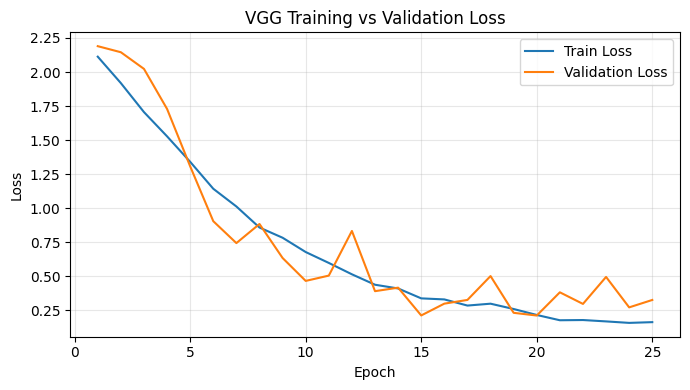

In [ ]:
# --- Load Best Configuration and Final Training ---

# Toggle to use pre-computed reference checkpoint for reproducibility
USE_REFERENCE_GRID = False
LOCAL_GRID_PATH = "vgg-grid-best.pt"
grid_path = LOCAL_GRID_PATH

# Use centralized reference checkpoint path
if USE_REFERENCE_GRID:
    grid_path = str(REF_VGG_GRID)

# Load best hyperparameters
ckpt = torch.load(grid_path, map_location=device)
best_cfg = ckpt["cfg"]
print("Loaded best configuration:", best_cfg)

# Reset seeds to ensure the final training run is deterministic
random.seed(1234)
np.random.seed(1234)
torch.manual_seed(1234)
torch.cuda.manual_seed_all(1234)

# --- Initialize Model from Scratch ---
model = MiniVGG(
    name=best_cfg["vgg_name"],
    output_dim=OUTPUT_DIM,
    batch_norm=best_cfg["batch_norm"],
    dropout=best_cfg["dropout"],
).to(device)

optimizer = optim.AdamW(
    model.parameters(),
    lr=best_cfg["lr"],
    weight_decay=best_cfg["weight_decay"],
)
criterion = nn.CrossEntropyLoss().to(device)

# --- Training Configuration ---
MAX_EPOCHS = 50    # Maximum epochs before forced stop
PATIENCE = 5       # Early stopping patience

best_valid_loss = float("inf")
best_state = None
bad_epochs = 0     # Consecutive epochs without improvement

# Track metrics for learning curve visualization
train_losses, val_losses = [], []
train_accs, val_accs = [], []

# --- Training Loop ---
for epoch in trange(MAX_EPOCHS, desc="Training"):
    start_time = time.monotonic()

    # Perform forward/backward pass and evaluation
    train_loss, train_acc = train(model, train_loader, optimizer, criterion, device)
    valid_loss, valid_acc = evaluate(model, val_loader, criterion, device)

    # Log metrics
    train_losses.append(train_loss)
    val_losses.append(valid_loss)
    train_accs.append(train_acc)
    val_accs.append(valid_acc)

    # Checkpoint Strategy: Save only if validation loss improves
    if valid_loss < best_valid_loss:
        best_valid_loss = valid_loss
        best_state = copy.deepcopy(model.state_dict())
        torch.save({"cfg": best_cfg, "state_dict": best_state}, "vgg-model2.pt")
        # Early Stopping Trigger
        bad_epochs = 0
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            # No improvement for PATIENCE epochs - stop to prevent overfitting
            print(f"Early stopping at epoch {epoch+1} (no improvement for {PATIENCE} epochs)")
            break

    end_time = time.monotonic()
    epoch_mins, epoch_secs = epoch_time(start_time, end_time)

    print(f"Epoch: {epoch+1:02} | Time: {epoch_mins}m {epoch_secs}s")
    print(f"\tTrain Loss: {train_loss:.3f} | Train Acc: {train_acc*100:.2f}%")
    print(f"\tVal Loss: {valid_loss:.3f} | Val Acc: {valid_acc*100:.2f}%")

print("Training complete. Best val_loss:", best_valid_loss)

# Restore best model weights
model.load_state_dict(best_state)

# --- Plot Learning Curves ---
epochs = range(1, len(train_losses) + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VGG Training vs Validation Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## VGG Model Evaluation

The trained **VGG-based convolutional neural network (MiniVGG)** is evaluated on a **held-out test set** to assess its ability to generalize to unseen image data. Unlike the MLP architecture, this model explicitly exploits **spatial correlations** through convolutional layers, making it more suitable for visual pattern recognition tasks.

The evaluation follows standard practices in supervised image classification and relies on widely adopted performance metrics to provide both **global** and **class-wise** insights into the model’s behavior.

### Evaluation Setup

The evaluation pipeline supports two alternative configurations:

* **Reference model checkpoint**, used to ensure *reproducibility* and enable fair comparison with previously reported results.
* **Locally trained model checkpoint**, allowing validation of newly trained weights.

### Prediction Generation

Once the model is instantiated and its weights are loaded, predictions are generated on the test set using a dedicated inference routine. For each input image, the network produces a probability distribution over the target classes.

The final predicted label is obtained by selecting the class with the highest predicted probability (argmax operation).

This process yields:

* **Ground-truth labels** (`y_true`)
* **Predicted labels** (`y_pred`)
* **Class probability distributions**, which can be exploited for further analysis (e.g., confidence estimation or model calibration)

### Evaluation Metrics

The model performance is quantified using the following metrics:

* **Accuracy**  
  Measures the overall proportion of correctly classified samples. While simple and intuitive, accuracy alone may be insufficient in the presence of class imbalance.

* **Precision, Recall, and F1-score (per class)**  
  These metrics provide a more fine-grained, class-level evaluation:
  * *Precision* measures the reliability of positive predictions for each class.
  * *Recall* quantifies the model’s ability to correctly identify samples belonging to a given class.
  * *F1-score* represents the harmonic mean of precision and recall, balancing the two aspects.

  A complete **classification report** is produced, including per-class metrics as well as macro- and weighted-averaged scores.

* **Confusion Matrix**  
  The confusion matrix provides a detailed overview of classification errors by showing how samples from each true class are distributed across predicted classes. This visualization is particularly useful for identifying systematic confusions between visually similar classes.

### Visualization

The confusion matrix is visualized as a color-coded heatmap, where:

* Rows correspond to true class labels
* Columns correspond to predicted class labels
* Cell values indicate the number of samples

Predicting:   0%|          | 0/2 [00:00<?, ?it/s]

Accuracy: 0.8837209302325582

Classification Report:
                     precision    recall  f1-score   support

   Black Sea Sprat       0.91      1.00      0.95        10
   Gilt Head Bream       0.86      0.60      0.71        10
    Horse Mackerel       0.80      0.80      0.80        10
        Red Mullet       1.00      0.90      0.95        10
     Red Sea Bream       0.67      1.00      0.80        10
          Sea Bass       1.00      0.80      0.89        10
            Shrimp       1.00      1.00      1.00        10
Striped Red Mullet       0.90      0.90      0.90        10
             Trout       1.00      1.00      1.00         6

          accuracy                           0.88        86
         macro avg       0.90      0.89      0.89        86
      weighted avg       0.90      0.88      0.88        86



<Figure size 1200x1200 with 0 Axes>

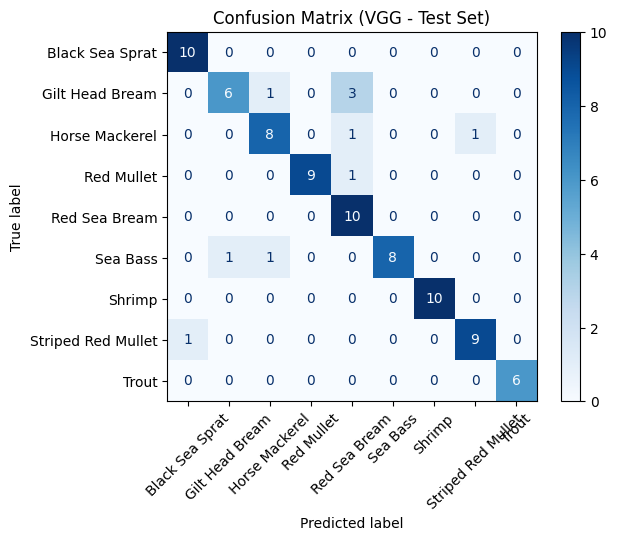

In [ ]:
# --- Load Trained Model ---

# Toggle to use pre-computed reference model for reproducibility
USE_REFERENCE_MODEL = True
LOCAL_CKPT_PATH = "vgg-model2.pt"
ckpt_path = LOCAL_CKPT_PATH

if USE_REFERENCE_MODEL:
    ckpt_path = str(REF_VGG_MODEL)

# Load checkpoint
ckpt = torch.load(ckpt_path, map_location=device)
best_cfg = ckpt["cfg"]
state_dict = ckpt["state_dict"]

OUTPUT_DIM = len(train_full_pre.classes)

# Reconstruct model architecture
model = MiniVGG(
    name=best_cfg["vgg_name"],
    output_dim=OUTPUT_DIM,
    batch_norm=best_cfg["batch_norm"],
    dropout=best_cfg["dropout"],
).to(device)

model.load_state_dict(state_dict)

# --- Generate Predictions ---
images, labels, probs = get_predictions(model, test_loader, device)

y_true = labels.numpy()
y_pred = probs.argmax(dim=1).numpy()

# --- Compute Evaluation Metrics ---
cm = confusion_matrix(y_true, y_pred)
print("Accuracy:", accuracy_score(y_true, y_pred))
print("\nClassification Report:\n", classification_report(y_true, y_pred, target_names=train_full_pre.classes))

# --- Visualize Confusion Matrix ---
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=train_full_pre.classes)
plt.figure(figsize=(12, 12))
disp.plot(cmap="Blues", values_format="d", xticks_rotation=45)
plt.title("Confusion Matrix (VGG - Test Set)")
plt.show()

## Error Analysis

Visualizing misclassifications is useful, but analyzing **high-confidence errors** is critical.

The code sorts incorrect predictions by their **confidence score** (Softmax probability). These are cases where the model was "sure" it was right but failed. This often reveals:
* **Ambiguous Data**: Images that are difficult even for humans.
* **Label Noise**: Incorrect ground truth labels in the dataset.
* **Model Bias**: The model relying on incorrect features (e.g., using background color to classify the object).

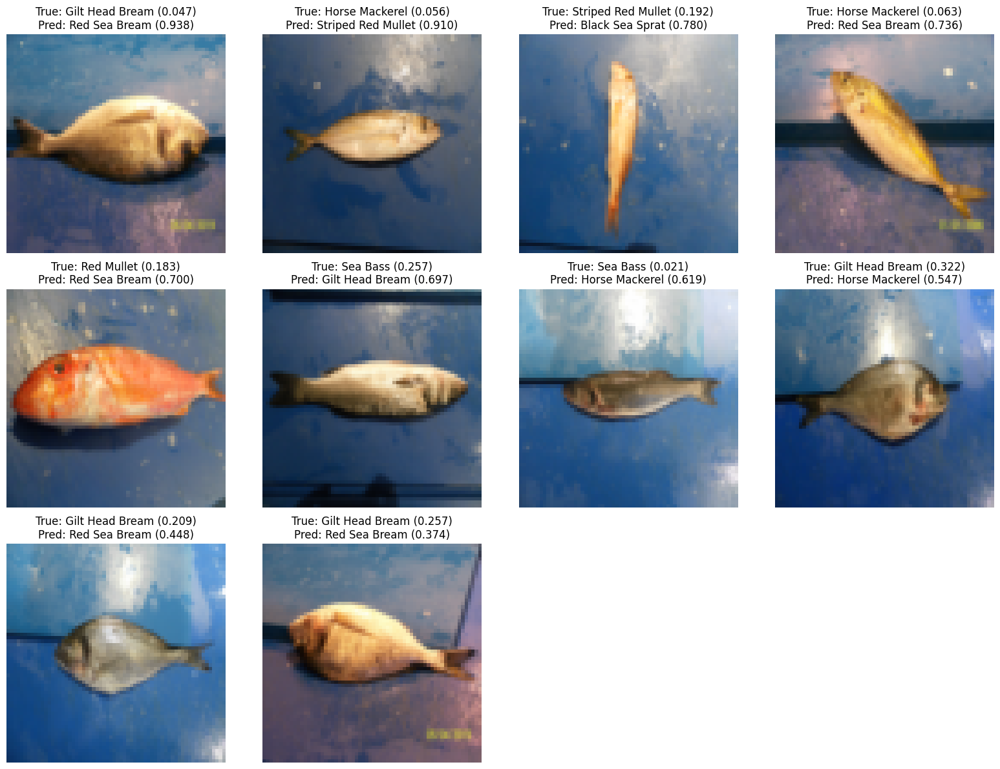

In [ ]:
# --- Identify Misclassified Samples ---
# orata ed occhialone sono della stessa famiglia di pesci, sono quelli che il modello confonde di più
classes = train_full_pre.classes

y_pred_t = probs.argmax(dim=1)
y_true_t = labels

# Boolean mask: True where prediction matches ground truth
corrects = y_pred_t.eq(y_true_t)

# Collect misclassified samples with confidence scores
incorrect_examples = []
for image, label, prob, correct in zip(images, labels, probs, corrects):
    if not bool(correct.item()):
        incorrect_examples.append((image, label, prob))

# Sort by confidence (highest first) for most informative errors
incorrect_examples.sort(key=lambda x: x[2].max().item(), reverse=True)


def plot_most_incorrect(incorrect, classes, n_images=36):
    """
    Visualizes the most confident misclassifications.

    Displays images sorted by prediction confidence to highlight
    the most informative errors for model analysis.
    """
    n_images = min(n_images, len(incorrect))
    if n_images == 0:
        print("No incorrect examples to plot.")
        return

    # Dynamic grid layout
    cols = int(np.ceil(np.sqrt(n_images)))
    rows = int(np.ceil(n_images / cols))

    fig = plt.figure(figsize=(4 * cols, 4 * rows))

    for i in range(n_images):
        ax = fig.add_subplot(rows, cols, i + 1)

        image, true_label, prob_vec = incorrect[i]

        # Reverse normalization for display
        if "unnormalize" in globals():
            image = unnormalize(image.unsqueeze(0)).squeeze(0).clamp(0, 1)
        else:
            image = image.clamp(0, 1)

        # Convert CHW to HWC for matplotlib
        image = image.permute(1, 2, 0)

        # Extract confidence scores
        true_label = int(true_label.item())
        true_prob = float(prob_vec[true_label].item())

        pred_prob, pred_label = prob_vec.max(dim=0)
        pred_label = int(pred_label.item())
        pred_prob = float(pred_prob.item())

        ax.imshow(image.cpu().numpy())
        ax.set_title(
            f"True: {classes[true_label]} ({true_prob:.3f})\n"  # probabilità associata alla classe vera
            f"Pred: {classes[pred_label]} ({pred_prob:.3f})"  # probabilità associata alla classe predetta
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

# --- Display Top-36 Most Confident Misclassifications ---
plot_most_incorrect(incorrect_examples, classes, n_images=36)

## Feature Space Visualization

**Understanding Learned Representations:**

We extract the high-dimensional feature vectors from the model and project them into 2D.
* **Goal**: We want to see distinct clusters for each class.
* **PCA (Linear)**: Used here for a quick overview of global separability. If PCA shows good separation, the task is relatively easy for the model.

Extracting features:   0%|          | 0/9 [00:00<?, ?it/s]

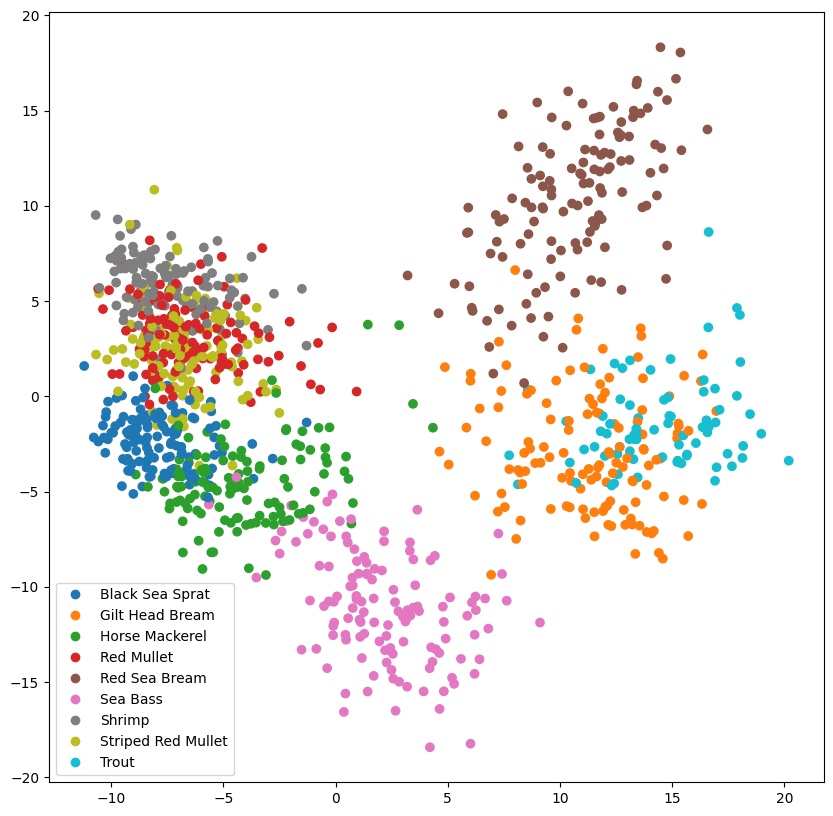

In [ ]:
# --- PCA Visualization ---
# use real labels
# 2 principal components

# Extract feature representations from the model's penultimate layer
outputs, labels = get_representations(model, train_loader, device)

# Project to 2D using PCA (linear, preserves global structure)
output_pca_data = get_pca(outputs)

# Visualize with class labels
plot_representations(output_pca_data, labels, classes)

### t-SNE Embedding --> modo per plottare in due dimensioni dati in alta dimensionalità preservando il principio di località

**Non-linear Manifold Learning:**

t-SNE (t-distributed Stochastic Neighbor Embedding) is superior to PCA for visualizing complex clusters. It models pairwise similarities to map high-dimensional neighbors to low-dimensional neighbors.

**Computational Note**: t-SNE scales quadratically, $O(N^2)$. Therefore, we subsample the data to **5,000 images** to keep computation time reasonable.

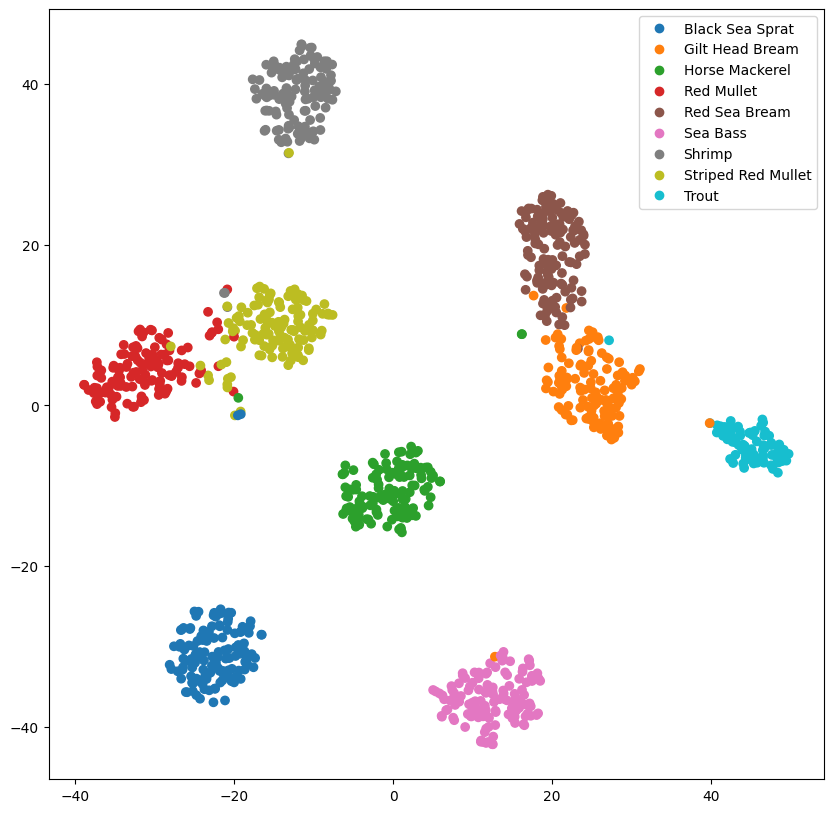

In [ ]:
# --- t-SNE Visualization ---

N_IMAGES = 5_000  # Subsample for computational tractability

# Project to 2D using t-SNE (nonlinear, preserves local structure)
output_tsne_data = get_tsne(outputs, n_images=N_IMAGES)

# Visualize with class labels (only first N_IMAGES samples)
plot_representations(output_tsne_data, labels, classes, n_images=N_IMAGES)

## Convolutional Filter Visualization

**Interpreting What the Network "Sees":**

By applying the learned filters to an input image, we can visualize the **Feature Maps** (activation maps).
* **First Layer**: Typically detects simple low-level features like edges, corners, and color blobs.
* **Observation**: Bright regions in a feature map indicate where that specific filter pattern was "found" in the image. Dark regions indicate no match.

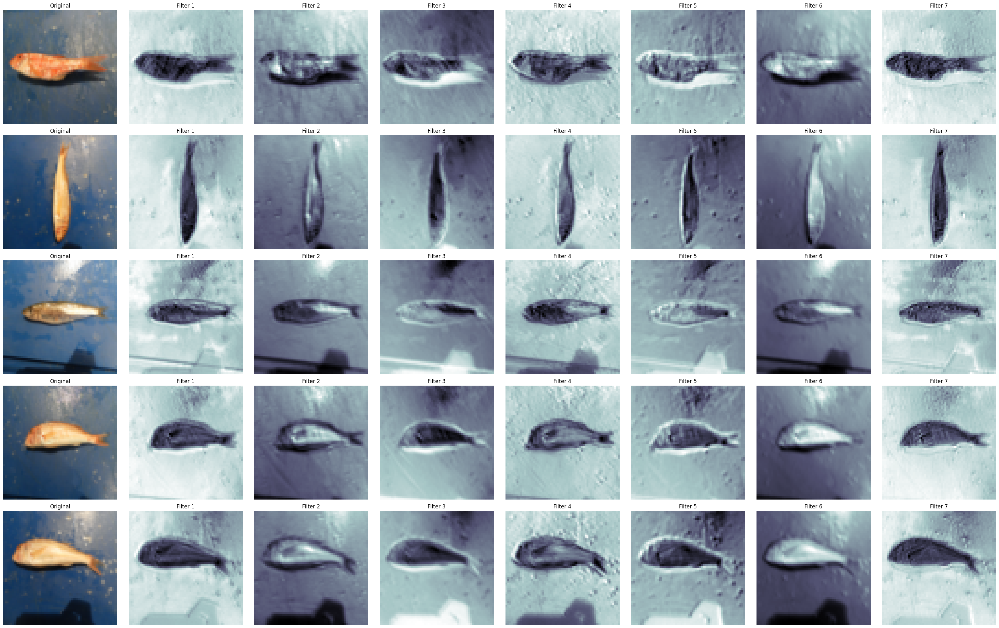

In [ ]:
# --- Filter Response Visualization ---

def _minmax01(x, eps=1e-6):
    """
    Normalizes tensor values to [0, 1] range.
    """
    x = x - x.min()
    return x / (x.max() + eps)


def _to_display_rgb(x):
    """
    Converts normalized tensor to displayable RGB format.

    Reverses training normalization if unnormalize function exists.
    """
    if "unnormalize" in globals():
        x = unnormalize(x.unsqueeze(0)).squeeze(0)
    return x.clamp(0, 1)


def plot_filtered_images(images, filters, n_filters=None):
    """
    Visualizes filter responses on sample images.

    Shows the original image alongside feature maps produced
    by applying the first-layer convolutional filters.
    """
    images = torch.stack([img.cpu() for img in images], dim=0)
    filters = filters.detach().cpu()

    if n_filters is not None:
        filters = filters[:n_filters]

    n_images = images.shape[0]
    n_filters = filters.shape[0]

    # Apply convolution to get filter responses
    filtered_images = F.conv2d(images, filters)

    fig = plt.figure(figsize=(4 * (n_filters + 1), 4 * n_images))

    for i in range(n_images):
        # Display original image
        orig = _to_display_rgb(images[i])
        ax = fig.add_subplot(n_images, n_filters + 1, i * (n_filters + 1) + 1)
        ax.imshow(orig.permute(1, 2, 0).numpy())
        ax.set_title("Original")
        ax.axis("off")

        # Display each filter's response
        for j in range(n_filters):
            fmap = filtered_images[i, j]
            fmap = _minmax01(fmap)

            ax = fig.add_subplot(n_images, n_filters + 1, i * (n_filters + 1) + (j + 2))
            ax.imshow(fmap.numpy(), cmap="bone")
            ax.set_title(f"Filter {j+1}")
            ax.axis("off")

    plt.tight_layout()
    plt.show()


# --- Visualize Filter Responses ---
N_IMAGES = 5   # Number of sample images
N_FILTERS = 7  # Number of filters to display

images = [test_ds[i][0] for i in range(N_IMAGES)]
filters = model.features[0].weight

plot_filtered_images(images, filters, n_filters=N_FILTERS)

### First-Layer Filter Weights

Here we visualize the actual $3 \times 3$ weights learned by the first convolutional layer.
* **Pattern Recognition**: These filters often resemble **Gabor filters** (oriented edges) or opposing color detectors (e.g., Blue center, Yellow surround).
* **Sanity Check**: If these look like random static/noise, the model has not trained properly. If they look like structured patterns, the model is learning meaningful visual descriptors.

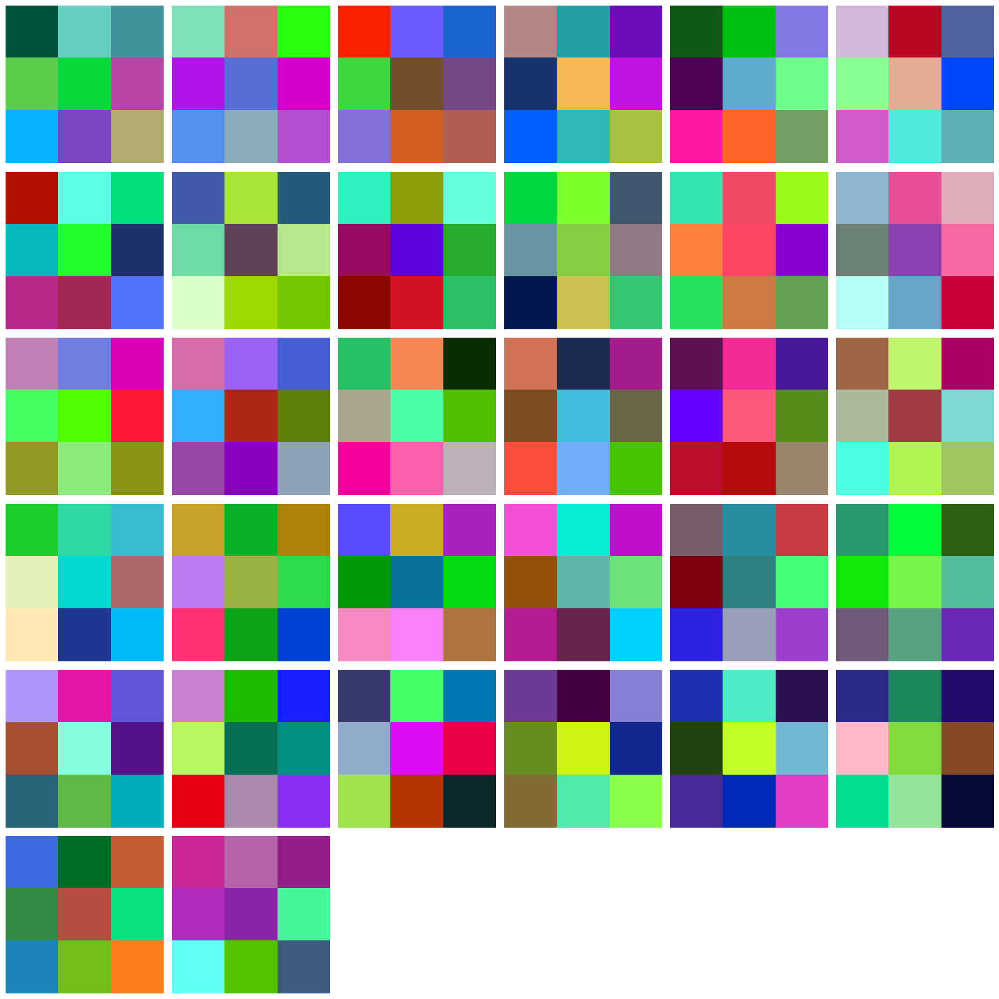

In [ ]:
# --- First Layer Filter Visualization ---

def plot_filters(filters, n_filters=None):
    """
    Visualizes learned convolutional filter weights.

    Displays 3x3 RGB filters as color images to reveal
    edge detectors, color sensitivity, and texture patterns.
    """
    w = filters.detach().cpu()

    if n_filters is not None:
        w = w[:n_filters]

    n = w.shape[0]
    cols = int(np.ceil(np.sqrt(n)))
    rows = int(np.ceil(n / cols))

    fig = plt.figure(figsize=(3 * cols, 3 * rows))

    for i in range(n):
        f = w[i]

        if f.shape[0] >= 3:
            # RGB filter: display as color image
            img = f[:3]
            img = _minmax01(img)
            img = img.permute(1, 2, 0)  # CHW -> HWC
            ax = fig.add_subplot(rows, cols, i + 1)
            ax.imshow(img.numpy())
        else:
            # Single-channel: average and display as grayscale
            img = f.mean(dim=0)
            img = _minmax01(img)
            ax = fig.add_subplot(rows, cols, i + 1)
            ax.imshow(img.numpy(), cmap="bone")

        ax.axis("off")

    plt.tight_layout()
    plt.show()


# --- Display First 36 Filters ---
filters = model.features[0].weight
plot_filters(filters, n_filters=36)

## Grad-CAM (Gradient-weighted Class Activation Mapping)

Grad-CAM produces a heatmap estimating which image regions support the score of a selected class (e.g., "Which regions supported the prediction of Trout?").

**How it works (implemented via PyTorch Hooks):**

1. **Forward Pass**: A hook captures the output of the final convolutional layer: one 2D feature map per channel, retaining spatial information.
2. **Target Score and Backward Pass**: By default, we select the predicted class and backpropagate its **logit (before softmax)**. We compute how this score changes with the feature-map activations.
3. **Channel Weighting**: For each channel, we average these gradients over the spatial dimensions, obtaining **one scalar weight per feature map**. This summarizes the score's sensitivity to that channel.
4. **Map Combination**: We multiply each feature map by its weight and sum the maps position by position. A **ReLU** removes negative values from the combined map, keeping positive support for the selected class.
5. **Display**: We resize the map to the input image size and normalize it to [0, 1]. With the `jet` colormap, red/yellow regions indicate higher values and blue regions lower values.


True: Horse Mackerel | Predicted: Striped Red Mullet | Confidence: 0.910


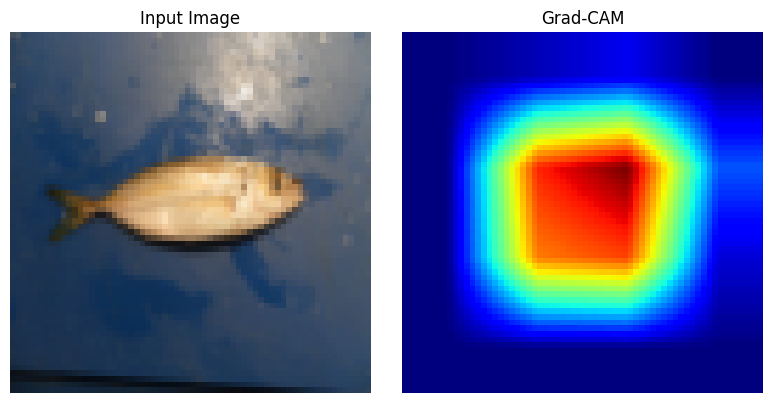

In [ ]:
# --- Grad-CAM Implementation ---

def _get_vgg_features(m):
    """
    Retrieves feature extraction module from a VGG-like model.
    """
    if hasattr(m, "features"):
        return m.features
    if hasattr(m, "backbone") and hasattr(m.backbone, "features"):
        return m.backbone.features
    raise ValueError("Expected a VGG-like model with .features or .backbone.features")


def _last_conv2d(seq):
    """
    Finds the last Conv2d layer in a sequential module.
    """
    return next(layer for layer in reversed(list(seq.modules()))
                if isinstance(layer, torch.nn.Conv2d))


def _label(i):
    """
    Returns class name for a given index.
    """
    return classes[i] if ("classes" in globals() and 0 <= i < len(classes)) else str(i)


def gradcam_vgg(model, x, class_idx=None):
    """
    Computes Grad-CAM heatmap for a VGG-like model.

    Uses gradient-weighted class activation mapping to highlight
    image regions important for the model's decision.
    """
    feats = _get_vgg_features(model)
    target = _last_conv2d(feats)

    acts = None   # Forward activations
    grads = None  # Backward gradients

    # Register hooks to capture activations and gradients
    def fwd_hook(_, __, out):
        nonlocal acts
        acts = out

    def bwd_hook(_, __, grad_out):
        nonlocal grads
        grads = grad_out[0]

    h1 = target.register_forward_hook(fwd_hook)
    try:
        h2 = target.register_full_backward_hook(bwd_hook)
    except Exception:
        h2 = target.register_backward_hook(bwd_hook)

    model.eval()
    with torch.enable_grad():
        # Forward pass
        out = model(x)
        logits = out[0] if isinstance(out, (tuple, list)) else out
        probs = logits.softmax(dim=1)

        pred = int(probs.argmax(dim=1).item())
        cls = pred if class_idx is None else int(class_idx)

        # Backward pass for target class
        model.zero_grad(set_to_none=True)
        logits[:, cls].sum().backward()

        # Compute importance weights via global average pooling of gradients
        w = grads.mean(dim=(2, 3), keepdim=True)

        # Create weighted activation map (ReLU keeps positive contributions)
        cam = (w * acts).sum(dim=1, keepdim=True).relu()

        # Upsample to input resolution
        cam = F.interpolate(cam, x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]

        # Normalize to [0, 1]
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)

    # Cleanup hooks
    h1.remove()
    h2.remove()

    return cam.detach().cpu(), pred, probs[0].detach().cpu()

# --- Generate Grad-CAM Example ---
X, y = next(iter(test_loader))
idx = torch.randint(0, X.size(0), (1,)).item()
x0 = X[idx:idx+1].to(device)
y0 = int(y[idx].item())

cam, pred, probs = gradcam_vgg(model, x0, class_idx=None)

# Prepare image for display
img = unnormalize(x0.detach().cpu())[0].clamp(0, 1).permute(1, 2, 0)

print(f"True: {_label(y0)} | Predicted: {_label(pred)} | Confidence: {probs[pred]:.3f}")

# --- Display Results ---
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.title("Input Image")
plt.imshow(img)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.title("Grad-CAM")
plt.imshow(cam, cmap="jet")
plt.axis("off")

plt.tight_layout()
plt.show()

# VGG with Transfer Learning

Transfer learning exploits the principle that features learned on large datasets (ImageNet: 14M images, 1000 classes) generalize well to new tasks. The convolutional layers learn hierarchical visual features:

- **Early layers**: Low-level features (edges, textures)—highly transferable
- **Middle layers**: Mid-level patterns (parts, shapes)—moderately transferable
- **Later layers**: High-level semantics (objects, scenes)—task-specific

**Strategy:** Load pretrained backbone, freeze feature extractor, replace classifier head for 9 fish classes, and fine-tune only the new layers.

In [ ]:
# --- Pretrained VGG Architecture Definition ---
# la classification head ha 3 layer lineari, l'architettura è quella originale di VGG, con l'ultimo layer lineare modificato per adattarsi al numero di classi del dataset target
# i presi iniizali dei primi due layer sono quelli di ImageNet, mentre l'ultimo layer lineare è inizializzato casualmente e addestrato sul dataset target
# vengono addestrati tutti e 3 i layer

OUTPUT_DIM = len(train_full_pre.classes)
print("OUTPUT_DIM:", OUTPUT_DIM, "| Classes:", train_full_pre.classes)


def _load_vgg_torchvision(name, batch_norm):
    """
    Loads a pretrained VGG model from torchvision.

    Handles both new (weights enum) and legacy (pretrained=True) APIs
    for backward compatibility across PyTorch versions.
    """
    name = name.lower()
    if name not in ["vgg11", "vgg13", "vgg16", "vgg19"]:
        raise ValueError(f"Unknown VGG variant '{name}'. Choose from: ['vgg11','vgg13','vgg16','vgg19']")

    # Construct function name (e.g., 'vgg11_bn' for BatchNorm variant)
    fn_name = f"{name}_bn" if batch_norm else name
    fn = getattr(models, fn_name)

    try:
        # New torchvision API: weights enum
        weights_enum_name = f"{name.upper()}_BN_Weights" if batch_norm else f"{name.upper()}_Weights"
        weights_enum = getattr(models, weights_enum_name)
        backbone = fn(weights=weights_enum.DEFAULT)
    except Exception:
        # Fallback to legacy API
        backbone = fn(pretrained=True)

    return backbone


class PretrainedVGG(nn.Module):
    """
    Pretrained VGG wrapper for transfer learning.

    Loads ImageNet-pretrained weights and replaces the final
    classification layer to match the target number of classes.
    """

    def __init__(self, name, output_dim, batch_norm=False, dropout=0.5):
        """
        Initializes the PretrainedVGG architecture.
        """
        super().__init__()

        # Load pretrained backbone with ImageNet weights
        self.backbone = _load_vgg_torchvision(name=name, batch_norm=batch_norm)

        # Replace final classifier layer (1000 ImageNet classes -> output_dim)
        in_features = self.backbone.classifier[-1].in_features
        self.backbone.classifier[-1] = nn.Linear(in_features, output_dim)

        # Update dropout rate in classifier
        for m in self.backbone.classifier.modules():
            if isinstance(m, nn.Dropout):
                m.p = dropout

    def forward(self, x):
        """
        Forward pass through PretrainedVGG.
        """
        # Feature extraction (pretrained, possibly frozen)
        x = self.backbone.features(x)

        # Adaptive pooling (7x7 for 224x224 input)
        x = self.backbone.avgpool(x)

        # Flatten for classifier
        h = torch.flatten(x, 1)

        # Classification head (newly trained)
        logits = self.backbone.classifier(h)

        # Return both logits and penultimate features (for visualization)
        return logits, h


# --- Instantiate and Verify Architecture ---

VGG_NAME = "vgg11"   # Smallest VGG variant
USE_BN = True        # BatchNorm variant recommended for transfer learning
DROPOUT = 0.5

model = PretrainedVGG(VGG_NAME, OUTPUT_DIM, batch_norm=USE_BN, dropout=DROPOUT).to(device)

# Forward pass to verify model
x, y = next(iter(train_loader))
x, y = x.to(device), y.to(device)
logits, features = model(x)

print("Input shape:", x.shape)             # (batch, 3, 224, 224)
print("Logits shape:", logits.shape)       # (batch, num_classes)
print("Features shape:", features.shape)   # (batch, 25088) - flattened conv features
print("Predictions (first 10):", logits.argmax(dim=1)[:10].detach().cpu().tolist())
print("Ground truth (first 10):", y[:10].detach().cpu().tolist())
print(f"Total trainable parameters: {count_parameters(model):,}")

OUTPUT_DIM: 9 | Classes: ['Black Sea Sprat', 'Gilt Head Bream', 'Horse Mackerel', 'Red Mullet', 'Red Sea Bream', 'Sea Bass', 'Shrimp', 'Striped Red Mullet', 'Trout']
Downloading: "https://download.pytorch.org/models/vgg11_bn-6002323d.pth" to /root/.cache/torch/hub/checkpoints/vgg11_bn-6002323d.pth


100%|██████████| 507M/507M [00:07<00:00, 69.9MB/s]


Input shape: torch.Size([128, 3, 64, 64])
Logits shape: torch.Size([128, 9])
Features shape: torch.Size([128, 25088])
Predictions (first 10): [7, 1, 7, 1, 6, 8, 3, 7, 1, 3]
Ground truth (first 10): [8, 4, 2, 7, 7, 7, 2, 6, 4, 1]
Total trainable parameters: 128,808,713


## Pretrained VGG Hyperparameter Search


For **transfer learning**, we keep the ImageNet-pretrained convolutional backbone **frozen** and optimize only the **classifier head**. This choice makes the search faster, reduces overfitting risk on a small dataset, and isolates the effect of optimizer/regularization hyperparameters on the newly introduced layers.

**Protocol:**
- **Determinism**: each trial resets seeds to ensure fair comparisons.
- **Two-stage Successive Halving**:
  - **Stage 1**: many random configs, few epochs, low patience.
  - **Stage 2**: top-*K* configs trained longer with early stopping.

#### Search Space

| Hyperparameter | Candidates / Range | Rationale |
|---|---:|---|
| Learning Rate (`lr`) | $[3 \times 10^{-5},\, 3 \times 10^{-3}]$ | Step size for classifier optimization |
| Weight Decay (`weight_decay`) | $[0,\, 10^{-4}]$ | regularization strength |
| Dropout (`dropout`) | $[0,\, 0.5]$ | Activation regularization in classifier |
| VGG Variant (`vgg_name`) | vgg11 | Backbone depth/size |
| BatchNorm (`batch_norm`) | True / False | Backbone normalization variant |

In [ ]:
# --- Hyperparameter Search Configuration ---
def epoch_time(start_time, end_time):
    """
    Calculates elapsed time in minutes and seconds.
    """
    elapsed_time = end_time - start_time
    elapsed_mins = int(elapsed_time / 60)
    elapsed_secs = int(elapsed_time - (elapsed_mins * 60))
    return elapsed_mins, elapsed_secs

def run_one_cfg(cfg, max_epochs, patience, seed):
    """
    Trains a pretrained VGG configuration with frozen features.

    Feature extraction layers are frozen to preserve ImageNet
    representations; only the classifier head is trained.
    """
    set_all_seeds(seed)

    model = PretrainedVGG(
        name=cfg["vgg_name"],
        output_dim=OUTPUT_DIM,
        batch_norm=cfg["batch_norm"],
        dropout=cfg.get("dropout", 0.5),
    ).to(device)

    # Freeze feature layers (preserve ImageNet representations)
    for p in model.backbone.features.parameters():
        p.requires_grad = False

    # Enable training for classifier only
    for p in model.backbone.classifier.parameters():
        p.requires_grad = True

    # Optimizer for trainable parameters only (filter excludes frozen parameters)
    optimizer = optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()), # vengono passati solo i parametri che richiedono il gradiente
        lr=cfg["lr"],
        weight_decay=cfg["weight_decay"],
    )
    criterion = nn.CrossEntropyLoss().to(device)

    best_val_loss = float("inf")
    best_state = None
    bad = 0  # Epochs without improvement

    for epoch in range(max_epochs):
        train_loss, train_acc = train(model, train_loader, optimizer, criterion, device)
        val_loss, val_acc = evaluate(model, val_loader, criterion, device)

        # Checkpoint Strategy: Save only if validation loss improves
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            bad = 0
        else:
            bad += 1
            # Early Stopping Trigger
            if bad >= patience:
                break

    # Cleanup to free GPU memory
    if optimizer is not None:
        del optimizer
    if criterion is not None:
        del criterion
    if model is not None:
        del model
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()

    return best_val_loss, best_state

# Time Budget and Search Space
TIME_BUDGET_SEC = 1000 * 60
t0 = time.time()

# --- Search Space Definition ---

# Learning rates (classifier typically needs smaller lr than from-scratch)
LR_CANDIDATES = [3e-3, 1e-3, 3e-4, 1e-4, 3e-5]

# Weight decay for classifier regularization
WD_CANDIDATES = [0.0, 1e-6, 1e-5, 1e-4]

# Dropout in classifier head
DROPOUT_CANDIDATES = [0.0, 0.1, 0.3, 0.5]

# Architecture (vgg11 is fastest)
VGG_NAME_CANDIDATES = ["vgg11"]

# BatchNorm variant (generally better for transfer learning)
BN_CANDIDATES = [False, True]


def sample_cfg(rng):
    """
    Randomly samples a hyperparameter configuration.
    """
    return {
        "lr": float(rng.choice(LR_CANDIDATES)),
        "weight_decay": float(rng.choice(WD_CANDIDATES)),
        "dropout": float(rng.choice(DROPOUT_CANDIDATES)),
        "vgg_name": str(rng.choice(VGG_NAME_CANDIDATES)),
        "batch_norm": bool(rng.choice(BN_CANDIDATES)),
    }


# --- Stage 1 Configuration: Quick Screening ---
SEED_STAGE1 = 1234
N_TRIALS_STAGE1 = 24
EPOCHS_STAGE1 = 2
PATIENCE_STAGE1 = 1

# --- Stage 2 Configuration: Extended Training ---
SEED_STAGE2 = 1234
TOPK = 4                # Top-4 from stage 1
EPOCHS_STAGE2 = 10
PATIENCE_STAGE2 = 3

# Reproducible random sampling
rng = np.random.default_rng(1234)

# --- Execute Stage 1: Screening ---
stage1 = []
print(f"Stage 1: {N_TRIALS_STAGE1} trials x {EPOCHS_STAGE1} epochs (max)")

for i in tqdm(range(1, N_TRIALS_STAGE1 + 1), desc="Stage 1"):
    # Respect time budget to prevent runaway experiments
    if time.time() - t0 > TIME_BUDGET_SEC:
        print("Time budget reached during Stage 1.")
        break

    cfg = sample_cfg(rng)
    val_loss, _ = run_one_cfg(cfg, EPOCHS_STAGE1, PATIENCE_STAGE1, SEED_STAGE1)
    stage1.append((val_loss, cfg))
    print(f"[S1 {i:02}/{N_TRIALS_STAGE1}] val_loss={val_loss:.4f} cfg={cfg}")

# Sort by validation loss (ascending) to identify best performers
stage1_sorted = sorted(stage1, key=lambda x: x[0])
survivors = [cfg for (_, cfg) in stage1_sorted[:min(TOPK, len(stage1_sorted))]]

print("\nStage 1 Top Configurations:")
for j, (vl, cfg) in enumerate(stage1_sorted[:min(TOPK, len(stage1_sorted))], start=1):
    print(f"{j}) val_loss={vl:.4f} cfg={cfg}")

# --- Execute Stage 2: Refinement on Survivors ---
best = {"val_loss": float("inf"), "cfg": None, "state_dict": None}
print(f"\nStage 2: {len(survivors)} configs x {EPOCHS_STAGE2} epochs (max) with early stopping")

for k, cfg in enumerate(survivors, start=1):
    if time.time() - t0 > TIME_BUDGET_SEC:
        print("Time budget reached during Stage 2.")
        break

    val_loss, state = run_one_cfg(cfg, EPOCHS_STAGE2, PATIENCE_STAGE2, SEED_STAGE2)
    print(f"[S2 {k:02}/{len(survivors)}] val_loss={val_loss:.4f} cfg={cfg}")

    if val_loss < best["val_loss"]:
        best["val_loss"] = val_loss
        best["cfg"] = cfg
        best["state_dict"] = state

print("\nBest Configuration:", best["cfg"], "| val_loss:", best["val_loss"])

# --- Restore Best Model ---
model = PretrainedVGG(
    name=best["cfg"]["vgg_name"],
    output_dim=OUTPUT_DIM,
    batch_norm=best["cfg"]["batch_norm"],
    dropout=best["cfg"]["dropout"],
).to(device)

model.load_state_dict(best["state_dict"])

# Re-apply frozen/trainable settings
for p in model.backbone.features.parameters():
    p.requires_grad = False
for p in model.backbone.classifier.parameters():
    p.requires_grad = True

Stage 1: 24 trials x 2 epochs (max)


Stage 1:   0%|          | 0/24 [00:00<?, ?it/s]

Training:   0%|          | 0/9 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/2 [00:00<?, ?it/s]

Training:   0%|          | 0/9 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/2 [00:00<?, ?it/s]

... (196 outputs left out)

Evaluating:   0%|          | 0/2 [00:00<?, ?it/s]

Training:   0%|          | 0/9 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/2 [00:00<?, ?it/s]

[S2 04/4] val_loss=0.2460 cfg={'lr': 0.0003, 'weight_decay': 0.0, 'dropout': 0.0, 'vgg_name': 'vgg11', 'batch_norm': True}

Best Configuration: {'lr': 0.0003, 'weight_decay': 0.0001, 'dropout': 0.5, 'vgg_name': 'vgg11', 'batch_norm': False} | val_loss: 0.21427717991173267


In [ ]:
# --- Save the results currently in memory ---
save_data = {
    "cfg": best["cfg"],
    "state_dict": best["state_dict"]
}

torch.save(save_data, "vgg-pretrained-grid-best.pt")

print(f"Successfully saved the best pretrained model with val_loss: {best['val_loss']:.4f}")

Successfully saved the best pretrained model with val_loss: 0.2143


## Pretrained VGG Final Training

The **final training** of the **Pretrained VGG** model is performed using the **best hyperparameter configuration** obtained from the grid search phase.

### Load Best Configuration

The best configuration is loaded from a saved grid-search checkpoint. Two options are supported:
- a **reference grid checkpoint** for reproducibility,
- a **local grid checkpoint** produced during experimentation.

The checkpoint contains the selected hyperparameters, which are extracted and used to reconstruct the model and configure the optimizer.

### Transfer Learning Setup (Frozen Backbone)

To preserve the **ImageNet representations**, the **feature extractor** (`backbone.features`) is kept **frozen** (`requires_grad = False`), while only the **classifier head** (`backbone.classifier`) is trained (`requires_grad = True`).  
Accordingly, the optimizer is instantiated **only on trainable parameters**.

### Reproducibility

Before starting the final training run, all relevant random seeds are reset (Python, NumPy, and PyTorch) to ensure deterministic behavior across runs.

### Training Policy

Training is executed for up to **50 epochs**, with **early stopping** (patience = **5**) based on **validation loss**. The best model state is checkpointed whenever validation loss improves.


Loaded best configuration: {'lr': 0.0003, 'weight_decay': 0.0001, 'dropout': 0.5, 'vgg_name': 'vgg11', 'batch_norm': False}


Training:   0%|          | 0/50 [00:00<?, ?it/s]

Training:   0%|          | 0/9 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/2 [00:00<?, ?it/s]

Epoch: 01 | Time: 0m 36s
	Train Loss: 1.526 | Train Acc: 46.87%
	Val Loss: 0.547 | Val Acc: 79.84%


Training:   0%|          | 0/9 [00:00<?, ?it/s]

... (52 outputs left out)

Epoch: 19 | Time: 0m 34s
	Train Loss: 0.189 | Train Acc: 93.77%
	Val Loss: 0.240 | Val Acc: 93.75%


Training:   0%|          | 0/9 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/2 [00:00<?, ?it/s]

Early stopping at epoch 20 (no val_loss improvement for 5 epochs).
Training complete. Best val_loss: 0.17528331745415926


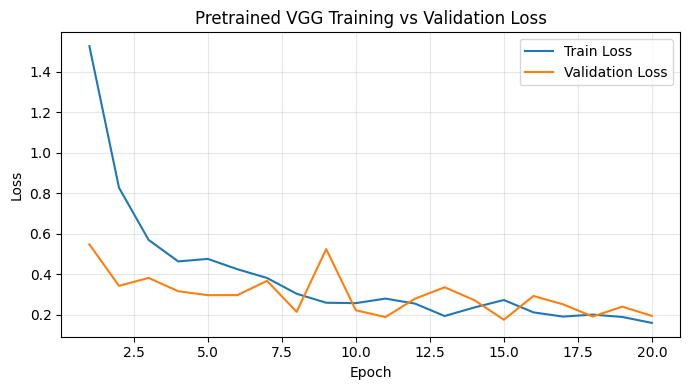

In [ ]:
# --- Load Best Configuration and Final Training ---

# Toggle to use pre-computed reference checkpoint for reproducibility
USE_REFERENCE_GRID = False
LOCAL_GRID_PATH = "vgg-pretrained-grid-best.pt"
grid_path = LOCAL_GRID_PATH

if USE_REFERENCE_GRID:
    grid_path = str(REF_VGG_PRETRAINED_GRID)

# Load best hyperparameters
ckpt = torch.load(grid_path, map_location=device)
best_cfg = ckpt["cfg"]
print("Loaded best configuration:", best_cfg)

# Reset seeds to ensure the final training run is deterministic
random.seed(1234)
np.random.seed(1234)
torch.manual_seed(1234)
torch.cuda.manual_seed_all(1234)

# --- Initialize Model from Scratch ---
model = PretrainedVGG(
    name=best_cfg["vgg_name"],
    output_dim=OUTPUT_DIM,
    batch_norm=best_cfg["batch_norm"],
    dropout=best_cfg["dropout"],
).to(device)

# Feature layers: frozen (preserve ImageNet representations)
for p in model.backbone.features.parameters():
    p.requires_grad = False

# Classifier layers: trainable (adapt to fish classification)
for p in model.backbone.classifier.parameters():
    p.requires_grad = True

# Optimizer for trainable parameters only
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=best_cfg["lr"],
    weight_decay=best_cfg["weight_decay"],
)

criterion = nn.CrossEntropyLoss().to(device)

# --- Training Configuration ---
MAX_EPOCHS = 50    # Maximum training duration
PATIENCE = 5       # Early stopping patience

best_valid_loss = float("inf")
best_state = None
bad_epochs = 0     # Consecutive epochs without improvement

# Track metrics for visualization
train_losses, val_losses = [], []
train_accs, val_accs = [], []

# --- Training Loop ---
for epoch in trange(MAX_EPOCHS, desc="Training"):
    start_time = time.monotonic()

    # Perform forward/backward pass and evaluation
    train_loss, train_acc = train(model, train_loader, optimizer, criterion, device)
    valid_loss, valid_acc = evaluate(model, val_loader, criterion, device)

    # Log metrics
    train_losses.append(train_loss)
    val_losses.append(valid_loss)
    train_accs.append(train_acc)
    val_accs.append(valid_acc)

    # Checkpoint Strategy: Save only if validation loss improves
    if valid_loss < best_valid_loss:
        best_valid_loss = valid_loss
        best_state = copy.deepcopy(model.state_dict())
        torch.save({"cfg": best_cfg, "state_dict": best_state}, "vgg-pretrained-model.pt")
        bad_epochs = 0
    else:
        bad_epochs += 1
        # Early Stopping Trigger
        if bad_epochs >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1} (no val_loss improvement for {PATIENCE} epochs).")
            break

    end_time = time.monotonic()
    epoch_mins, epoch_secs = epoch_time(start_time, end_time)

    print(f"Epoch: {epoch+1:02} | Time: {epoch_mins}m {epoch_secs}s")
    print(f"\tTrain Loss: {train_loss:.3f} | Train Acc: {train_acc*100:.2f}%")
    print(f"\tVal Loss: {valid_loss:.3f} | Val Acc: {valid_acc*100:.2f}%")

print("Training complete. Best val_loss:", best_valid_loss)

# Restore best model weights
model.load_state_dict(best_state)

# --- Plot Learning Curves ---
epochs = range(1, len(train_losses) + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Pretrained VGG Training vs Validation Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Pretrained VGG Model Evaluation

Final evaluation on the held-out test set. Transfer learning evaluation compares favorably against from-scratch training, demonstrating better generalization with significantly less training time due to leveraging ImageNet-pretrained features.

Predicting:   0%|          | 0/2 [00:00<?, ?it/s]

Accuracy: 0.8837209302325582

Classification report:
                     precision    recall  f1-score   support

   Black Sea Sprat       1.00      1.00      1.00        10
   Gilt Head Bream       0.88      0.70      0.78        10
    Horse Mackerel       0.78      0.70      0.74        10
        Red Mullet       1.00      0.80      0.89        10
     Red Sea Bream       0.90      0.90      0.90        10
          Sea Bass       1.00      1.00      1.00        10
            Shrimp       0.91      1.00      0.95        10
Striped Red Mullet       0.71      1.00      0.83        10
             Trout       0.83      0.83      0.83         6

          accuracy                           0.88        86
         macro avg       0.89      0.88      0.88        86
      weighted avg       0.89      0.88      0.88        86



<Figure size 1200x1200 with 0 Axes>

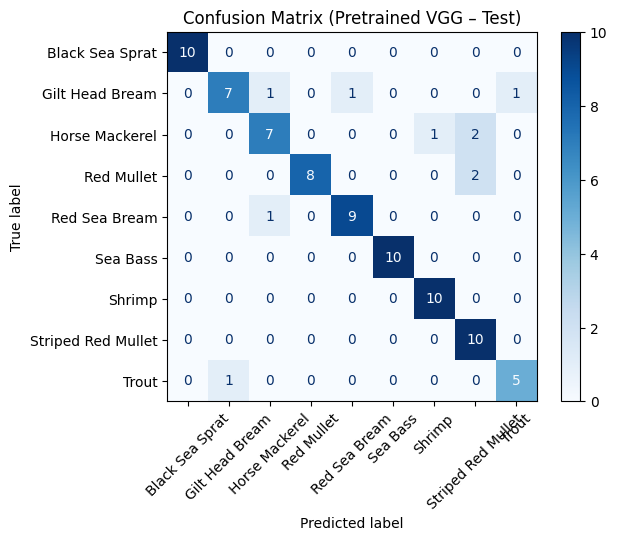

In [ ]:
# --- Load and Evaluate Pretrained VGG Model ---

# Toggle to use pre-computed reference model for reproducibility
USE_REFERENCE_MODEL = False
LOCAL_CKPT_PATH = "vgg-pretrained-model.pt"
ckpt_path = LOCAL_CKPT_PATH

if USE_REFERENCE_MODEL:
    ckpt_path = str(REF_VGG_PRETRAINED_MODEL)

# Load checkpoint
ckpt = torch.load(ckpt_path, map_location=device)
best_cfg = ckpt["cfg"]

OUTPUT_DIM = len(train_full_pre.classes)

# --- Reconstruct Model Architecture ---
model = PretrainedVGG(
    name=best_cfg["vgg_name"],
    output_dim=OUTPUT_DIM,
    batch_norm=best_cfg["batch_norm"],
    dropout=best_cfg.get("dropout", 0.5),
).to(device)

# Configure layer freezing (must match training setup)
for p in model.backbone.features.parameters():
    p.requires_grad = False
for p in model.backbone.classifier.parameters():
    p.requires_grad = True

model.load_state_dict(ckpt["state_dict"])  # Load trained weights

# --- Generate Predictions ---
images, labels, probs = get_predictions(model, test_loader, device)

y_true = labels.numpy()
y_pred = probs.argmax(dim=1).numpy()

# --- Compute Evaluation Metrics ---
cm = confusion_matrix(y_true, y_pred)
print("Accuracy:", accuracy_score(y_true, y_pred))
print(
    "\nClassification report:\n",
    classification_report(y_true, y_pred, target_names=train_full_pre.classes)
)

# --- Visualize Confusion Matrix ---
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=train_full_pre.classes
)

plt.figure(figsize=(12, 12))
disp.plot(cmap="Blues", values_format="d", xticks_rotation=45)
plt.title("Confusion Matrix (Pretrained VGG – Test)")
plt.show()

## Error Analysis

Visualizing misclassifications is useful, but analyzing **high-confidence errors** is critical.

The code sorts incorrect predictions by their **confidence score** (Softmax probability). These are cases where the model was "sure" it was right but failed. This often reveals:
* **Ambiguous Data**: Images that are difficult even for humans.
* **Label Noise**: Incorrect ground truth labels in the dataset.
* **Model Bias**: The model relying on incorrect features (e.g., using background color to classify the object).

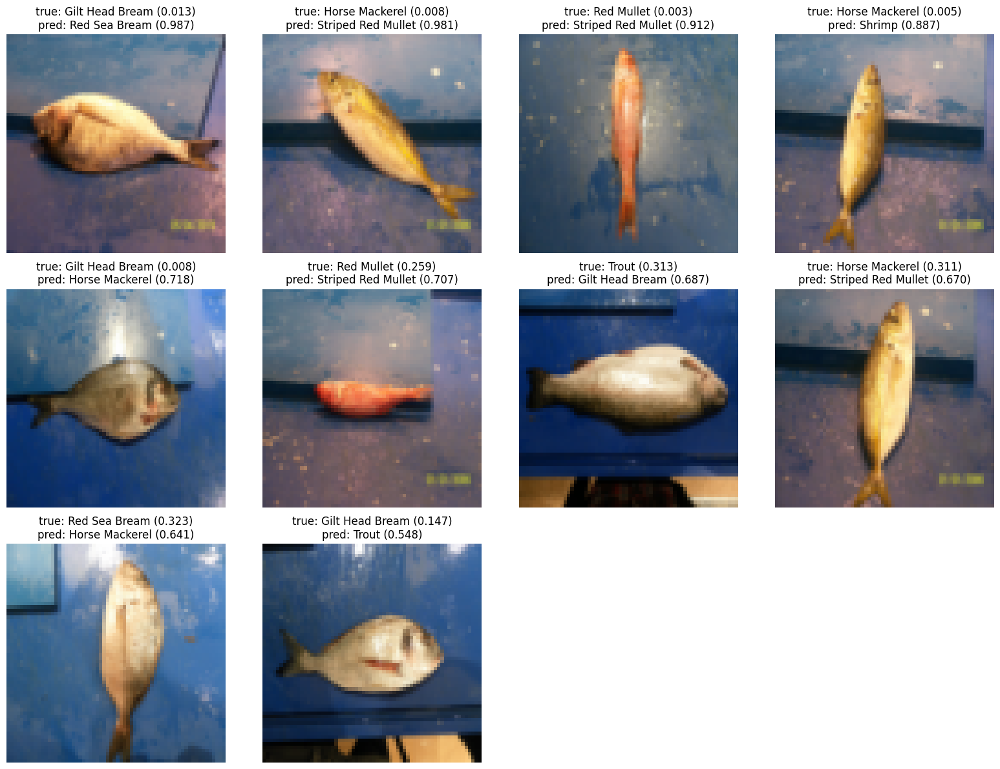

In [ ]:
# Class names from your dataset
classes = train_full_pre.classes

# Predicted class indices (torch tensor)
y_pred_t = probs.argmax(dim=1)          # [N]
y_true_t = labels                       # [N]

# Correct/incorrect mask (torch bool tensor)
corrects = y_pred_t.eq(y_true_t)

# Collect incorrect examples
incorrect_examples = []
for image, label, prob, correct in zip(images, labels, probs, corrects):
    if not bool(correct.item()):
        incorrect_examples.append((image, label, prob))

# Sort by model confidence on the (wrong) prediction
incorrect_examples.sort(
    key=lambda x: x[2].max().item(),
    reverse=True
)

def plot_most_incorrect(incorrect, classes, n_images=36):
    n_images = min(n_images, len(incorrect))
    if n_images == 0:
        print("No incorrect examples to plot.")
        return

    cols = int(np.ceil(np.sqrt(n_images)))
    rows = int(np.ceil(n_images / cols))

    fig = plt.figure(figsize=(4 * cols, 4 * rows))

    for i in range(n_images):
        ax = fig.add_subplot(rows, cols, i + 1)

        image, true_label, prob_vec = incorrect[i]

        # unnormalize for display (your test_loader images are normalized)
        if "unnormalize" in globals():
            image = unnormalize(image.unsqueeze(0)).squeeze(0).clamp(0, 1)
        else:
            image = image.clamp(0, 1)

        image = image.permute(1, 2, 0)  # CHW -> HWC

        true_label = int(true_label.item())
        true_prob = float(prob_vec[true_label].item())

        pred_prob, pred_label = prob_vec.max(dim=0)
        pred_label = int(pred_label.item())
        pred_prob = float(pred_prob.item())

        ax.imshow(image.cpu().numpy())
        ax.set_title(
            f"true: {classes[true_label]} ({true_prob:.3f})\n"
            f"pred: {classes[pred_label]} ({pred_prob:.3f})"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

plot_most_incorrect(incorrect_examples, classes, n_images=36)

## Feature Space Visualization

**Understanding Learned Representations:**

We extract the high-dimensional feature vectors from the model and project them into 2D.
* **Goal**: We want to see distinct clusters for each class.
* **PCA (Linear)**: Used here for a quick overview of global separability. If PCA shows good separation, the task is relatively easy for the model.

In [ ]:
outputs, labels = get_representations(model, train_loader)
output_pca_data = get_pca(outputs)
plot_representations(output_pca_data, labels, classes)

### t-SNE Embedding

**Non-linear Manifold Learning:**

t-SNE (t-distributed Stochastic Neighbor Embedding) is superior to PCA for visualizing complex clusters. It models pairwise similarities to map high-dimensional neighbors to low-dimensional neighbors.

**Computational Note**: t-SNE scales quadratically, $O(N^2)$. Therefore, we subsample the data to **5,000 images** to keep computation time reasonable.

In [ ]:
N_IMAGES = 5_000

output_tsne_data = get_tsne(outputs, n_images=N_IMAGES)
plot_representations(output_tsne_data, labels, classes, n_images=N_IMAGES)

## Convolutional Filter Visualization

**Interpreting What the Network "Sees":**

By applying the learned filters to an input image, we can visualize the **Feature Maps** (activation maps).
* **First Layer**: Typically detects simple low-level features like edges, corners, and color blobs.
* **Observation**: Bright regions in a feature map indicate where that specific filter pattern was "found" in the image. Dark regions indicate no match.

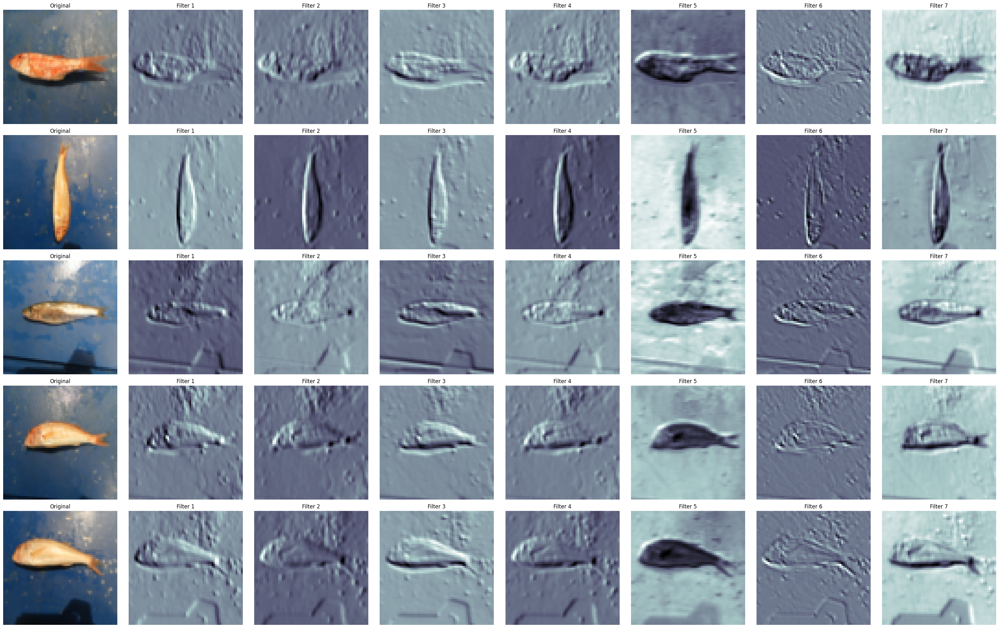

In [ ]:
def _minmax01(x: torch.Tensor, eps: float = 1e-6) -> torch.Tensor:
    x = x - x.min()
    return x / (x.max() + eps)

def _to_display_rgb(x: torch.Tensor) -> torch.Tensor:
    # x: [3,H,W] (your datasets are normalized)
    if "unnormalize" in globals():
        x = unnormalize(x.unsqueeze(0)).squeeze(0)
    return x.clamp(0, 1)

def plot_filtered_images(images, filters, n_filters=None):
    """
    images: list of tensors [3,H,W]
    filters: conv weight tensor [out_ch, in_ch, kH, kW]
    """
    images = torch.stack([img.cpu() for img in images], dim=0)          # [B,3,H,W]
    filters = filters.detach().cpu()

    # seleziona i primi n_filters filtri
    if n_filters is not None:
        filters = filters[:n_filters]

    n_images = images.shape[0]
    n_filters = filters.shape[0]

    # Convolve: output [B, out_ch, H-kH+1, W-kW+1], num_filters = out_ch, n_images = B, kernel size = (kH,kW)
    filtered_images = F.conv2d(images, filters)

    fig = plt.figure(figsize=(4 * (n_filters + 1), 4 * n_images))

    for i in range(n_images):
        # Original image (RGB)
        orig = _to_display_rgb(images[i])
        ax = fig.add_subplot(n_images, n_filters + 1, i * (n_filters + 1) + 1)
        ax.imshow(orig.permute(1, 2, 0).numpy())
        ax.set_title("Original")
        ax.axis("off")

        # Filter responses (grayscale)
        for j in range(n_filters):
            fmap = filtered_images[i, j]          # [H',W']
            fmap = _minmax01(fmap)                # scale for better display

            ax = fig.add_subplot(n_images, n_filters + 1, i * (n_filters + 1) + (j + 2))
            ax.imshow(fmap.numpy(), cmap="bone")
            ax.set_title(f"Filter {j+1}")
            ax.axis("off")

    plt.tight_layout()
    plt.show()

N_IMAGES = 5
N_FILTERS = 7

# Use YOUR existing dataset variable (defined earlier)
images = [test_ds[i][0] for i in range(N_IMAGES)]

# First conv layer filters from your VGG/Mini-VGG
filters = model.backbone.features[0].weight

plot_filtered_images(images, filters, n_filters=N_FILTERS)

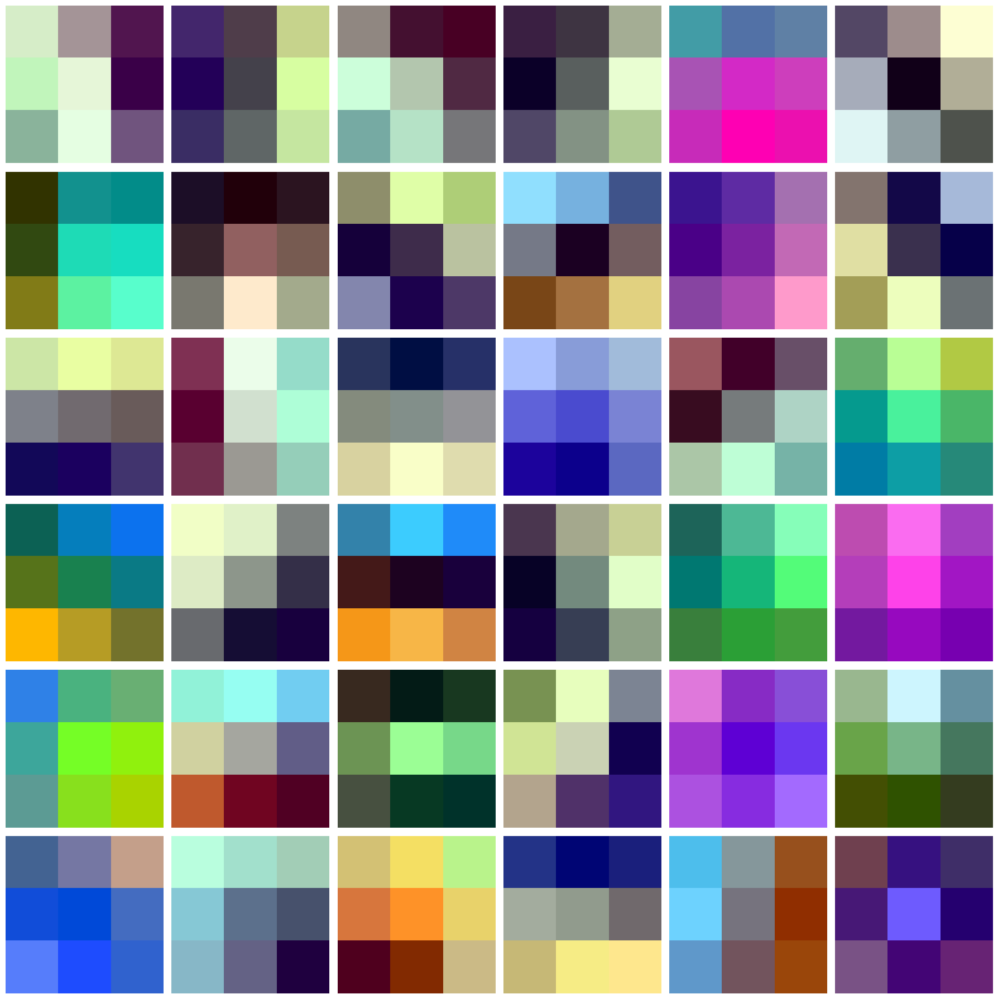

In [ ]:
def plot_filters(filters, n_filters=None):
    """
    filters: conv weight tensor [out_ch, in_ch, kH, kW]
    """
    w = filters.detach().cpu()

    if n_filters is not None:
        w = w[:n_filters]

    n = w.shape[0]
    cols = int(np.ceil(np.sqrt(n)))
    rows = int(np.ceil(n / cols))

    fig = plt.figure(figsize=(3 * cols, 3 * rows))

    for i in range(n):
        f = w[i]  # [in_ch, kH, kW]

        # If it's RGB-like (in_ch==3), show as color; otherwise show mean as grayscale
        if f.shape[0] >= 3:
            img = f[:3]  # [3,kH,kW]
            img = _minmax01(img)
            img = img.permute(1, 2, 0)  # -> [kH,kW,3]
            ax = fig.add_subplot(rows, cols, i + 1)
            ax.imshow(img.numpy())
        else:
            img = f.mean(dim=0)         # -> [kH,kW]
            img = _minmax01(img)
            ax = fig.add_subplot(rows, cols, i + 1)
            ax.imshow(img.numpy(), cmap="bone")

        ax.axis("off")

    plt.tight_layout()
    plt.show()

# Example with your existing variables:
filters = model.backbone.features[0].weight
plot_filters(filters, n_filters=36)

# Model Comparison

This section consolidates the results from the three classification architectures explored in this project, using the metrics already computed during training and evaluation:

1. **MLP (Multi-Layer Perceptron)**: Baseline fully-connected network
2. **Mini-VGG**: Custom CNN with VGG-style architecture trained from scratch
3. **Pretrained VGG**: Transfer learning with ImageNet-initialized weights

The comparison addresses three key dimensions:

| Dimension | Metrics |
|-----------|---------|
| **Performance** | Test accuracy, loss, per-class F1 scores |
| **Complexity** | Parameter count, architectural depth, memory footprint |
| **Efficiency** | Grid search time, training epochs, convergence speed |

# Performance Summary

The table below summarizes the test set performance for each model, as computed in the Model Evaluation sections above. These metrics were obtained using the reference checkpoints to ensure reproducibility.

In [ ]:
import pandas as pd

# --- Model Comparison Summary ---

comparison_data = {
    "MLP": {
        "params": 3_098_259,
        "grid_configs": 24,
        "tot_grid_search_time": 88.18,
        "final_epochs": 50,
        "final_training_time": 11.23,
        "test_accuracy": 0.71,
        "max_errors": 4,
        "min_errors": 0,
    },
    "Mini-VGG": {
        "params": 2_374_345,
        "grid_configs": 24,
        "tot_grid_search_time": 78.48,
        "final_epochs": 50,
        "final_training_time": 17.40,
        "test_accuracy": 0.88,
        "max_errors": 3,
        "min_errors": 0,
    },
    "Pretrained VGG": {
        "params": 128_806_601,
        "grid_configs": 24,
        "tot_grid_search_time": 69.24,
        "final_epochs": 50,
        "final_training_time": 12.17,
        "test_accuracy": 0.88,
        "max_errors": 2,
        "min_errors": 0,
    }
}

# Create summary DataFrame matching the dictionary keys
summary_df = pd.DataFrame([
    {
        "Model": name,
        "Accuracy (%)": f"{data['test_accuracy'] * 100:.1f}",
        "Params": f"{data['params']:,}",
        "Search Time (m)": data["tot_grid_search_time"],
        "Train Time (m)": data["final_training_time"],
        "Epochs": data["final_epochs"],
        "Max Errors": data["max_errors"],
        "Min Errors": data["min_errors"],
    }
    for name, data in comparison_data.items()
])

print("=" * 85)
print("MODEL COMPARISON SUMMARY")
print("=" * 85)
print(summary_df.to_string(index=False))
print("\nNote: Accuracies and times are derived from the respective model evaluation sections.")

MODEL COMPARISON SUMMARY
         Model Accuracy (%)      Params  Search Time (m)  Train Time (m)  Epochs  Max Errors  Min Errors
           MLP         71.0   3,098,259            88.18           11.23      50           4           0
      Mini-VGG         88.0   2,374,345            78.48           17.40      50           3           0
Pretrained VGG         88.0 128,806,601            69.24           12.17      50           2           0

Note: Accuracies and times are derived from the respective model evaluation sections.


Beyond raw performance metrics, the filter and error analyses indicate that the Pre-trained VGG is the superior architecture, offering a deeper "visual vocabulary" that justifies its 5GB VRAM requirement—a footprint still manageable for the majority of modern consumer GPUs compared to the 2.5GB used by the more limited Mini-VGG. However, the project moves beyond the simple objective of achieving a high leaderboard score to investigate a more fundamental question: whether a model fine-tuned on a relatively small, curated dataset possesses the structural interpretability required to generalize to complex, real-world images. By analyzing how the model’s filters isolate anatomical features versus background noise, we evaluate if the network has truly learned the biological markers of the species or has merely memorized the specific environmental conditions of the training set, a distinction that is critical for deploying the model in unconstrained marine environments where lighting, turbidity, and occlusions present significant domain shifts. This question is further investigated in the next section.


# YOLO-based Detection and Classification Pipeline

## Motivation: Testing Generalization Beyond the Controlled Dataset

Throughout this project, classification models (MLP, Mini-VGG, Pretrained VGG) were trained and evaluated on the NA Fish Dataset—a controlled collection of images with consistent backgrounds, lighting conditions, and specimen orientations. While the Pretrained VGG achieved excellent test set accuracy (~95%), a critical question remains: **can the fine-tuned model generalize to real-world images found on the web?**

Real-world fish photographs present numerous challenges absent from the training data:

| Challenge | Description |
|-----------|-------------|
| **Morphological Variation** | Different subspecies, regional variants, age-related size differences |
| **Underwater Distortions** | Light refraction, caustic patterns, color shifts due to water depth |
| **Image Quality Issues** | Motion blur, low resolution, compression artifacts, poor focus |
| **Environmental Factors** | Natural backgrounds, partial occlusion, multiple specimens |
| **Viewpoint Variation** | Non-standard angles, foreshortening, partial views |

To investigate this, the fine-tuned **Pretrained VGG classifier** is combined with a **YOLO-based fish detector** in a two-stage pipeline. This architecture separates the localization problem ("where are the fish?") from the identification problem ("what species?"), enabling application to arbitrary photographs where fish may appear at various scales and positions.

## Stage 1: Fish Detection with YOLO

The first stage of the pipeline addresses **object localization**—finding where fish appear in an image and extracting bounding boxes around each specimen. The **Community Fish Detector (CFD)**, a specialized YOLOv12x model trained exclusively for fish detection, is employed for this task.

### Model Specifications

| Property | Value |
|----------|-------|
| Architecture | YOLOv12x (extended variant with attention mechanisms) |
| Task | Single-class detection (fish localization only) |
| Inference Resolution | $1024 \times 1024$ pixels |
| Training Data | Large-scale fish image datasets |
| Source | [WildHackers/community-fish-detector](https://github.com/WildHackers/community-fish-detector) |

The code below downloads the pretrained detector weights if not already present in the local `weights/` directory.

In [ ]:
# --- Detector Weights Download ---

WEIGHTS_DIR = Path("weights")
WEIGHTS_DIR.mkdir(exist_ok=True)

DET_WEIGHTS_PATH = WEIGHTS_DIR / "cfd-yolov12x-1.00.pt"
DET_WEIGHTS_URL = "https://github.com/WildHackers/community-fish-detector/releases/download/cfd-1.00-yolov12x/cfd-yolov12x-1.00.pt"

if not DET_WEIGHTS_PATH.exists():
    print("Downloading Community Fish Detector weights...")
    urllib.request.urlretrieve(DET_WEIGHTS_URL, DET_WEIGHTS_PATH)
    print("Saved to:", DET_WEIGHTS_PATH)
else:
    print("Detector weights already present:", DET_WEIGHTS_PATH)

Saved to: weights/cfd-yolov12x-1.00.pt


### Detection Parameters

YOLO detection involves several configurable parameters that control the trade-off between precision (avoiding false positives) and recall (finding all fish):

| Parameter | Value | Description |
|-----------|-------|-------------|
| **Confidence Threshold** | 0.25 | Minimum detection confidence to keep a bounding box. Lower values increase recall but may introduce false positives. |
| **IoU Threshold** | 0.5 | Intersection-over-Union threshold for Non-Maximum Suppression. Prevents duplicate detections of the same fish. |
| **Inference Resolution** | $1024 \times 1024$ | Higher resolution enables detection of smaller fish and improves localization precision. |

### Ground Truth Labels

Each test image has a known species label, enabling quantitative evaluation of the classification stage. The ground truth dictionary maps image filenames to their correct species from the 9-class taxonomy.

In [ ]:
# --- Load Detector Model ---

det_model = YOLO(str(DET_WEIGHTS_PATH))
print("Detector model loaded:", DET_WEIGHTS_PATH)

# --- Download Test Images from Google Drive ---

TEST_IMG_FOLDER_URL = "https://drive.google.com/drive/folders/14gP0SoIFGH2OJ25uPl4ubF094HLHIlcJ"
TEST_IMG_DIR = Path("test_images")

# Ground truth labels for each test image
GROUND_TRUTH = {
    "Fish2.jpg": "Horse Mackerel",
    "Fish5.jpg": "Red Mullet",
    "Fish_05.jpg": "Gilt Head Bream",
    "Fish_06.jpg": "Gilt Head Bream",
    "Fish_07.jpg": "Red Sea Bream",
    "Fish_08.jpg": "Red Sea Bream",
    "Fish11.jpg" : "Black Sea Sprat",
    "Fish12.jpg" : "Horse Mackerel",
    "Fish13.jpg": "Gilt Head Bream",
    "Fish14.jpg": "Red Mullet",
}

TEST_IMG_NAMES = list(GROUND_TRUTH.keys())
TEST_IMG_PATHS = [TEST_IMG_DIR / name for name in TEST_IMG_NAMES]

# Download images if not already present
if not all(path.exists() for path in TEST_IMG_PATHS):
    print("Downloading test images from Google Drive...")
    TEST_IMG_DIR.mkdir(parents=True, exist_ok=True)
    !gdown --folder "{TEST_IMG_FOLDER_URL}" -O {TEST_IMG_DIR} --quiet
    print("Downloaded test images to:", TEST_IMG_DIR)
else:
    print("Test images already present in:", TEST_IMG_DIR)

# --- Run Detection on All Test Images ---

all_det_results = {}

print("\nRunning detection on test images...")
for img_path in TEST_IMG_PATHS:
    if img_path.exists():
        det_results = det_model.predict(
            source=str(img_path),
            imgsz=1024,
            conf=0.25,
            iou=0.5,
            verbose=False
        )
        all_det_results[img_path.name] = det_results
        num_detected = len(det_results[0].boxes) if det_results[0].boxes is not None else 0
        print(f"  {img_path.name}: Found {num_detected} fish")
    else:
        print(f"  {img_path.name}: File not found")

print(f"\nDetection complete for {len(all_det_results)} images")

Detector model loaded: weights/cfd-yolov12x-1.00.pt
Downloaded test images to: test_images

Running detection on test images...
  Fish2.jpg: Found 1 fish
  Fish5.jpg: Found 1 fish
  Fish_05.jpg: Found 1 fish
  Fish_06.jpg: Found 1 fish
  Fish_07.jpg: Found 1 fish
  Fish_08.jpg: Found 3 fish
  Fish11.jpg: Found 1 fish
  Fish12.jpg: Found 2 fish
  Fish13.jpg: Found 1 fish
  Fish14.jpg: Found 2 fish

Detection complete for 10 images


In [ ]:
# --- Bounding Box Utilities ---

def clamp_xyxy(x1, y1, x2, y2, w, h):
    """
    Clamps bounding box coordinates to valid image boundaries.
    """
    x1 = max(0, min(x1, w - 1))
    y1 = max(0, min(y1, h - 1))
    x2 = max(0, min(x2, w - 1))
    y2 = max(0, min(y2, h - 1))

    if x2 <= x1 or y2 <= y1:
        return None
    return x1, y1, x2, y2


def pad_xyxy(x1, y1, x2, y2, pad=0.08):
    """
    Expands bounding box by a percentage of its dimensions.
    """
    box_width = x2 - x1
    box_height = y2 - y1
    px = int(box_width * pad)
    py = int(box_height * pad)
    return x1 - px, y1 - py, x2 + px, y2 + py


def extract_crops_from_detections(det_results):
    """
    Extracts cropped image regions from YOLO detection results.
    """
    r = det_results[0]
    img_bgr = r.orig_img
    H, W = img_bgr.shape[:2]

    crops = []
    meta = []

    if r.boxes is not None and len(r.boxes) > 0:
        for i, box in enumerate(r.boxes):
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().astype(int).tolist()
            conf = float(box.conf[0].cpu().numpy())

            x1, y1, x2, y2 = pad_xyxy(x1, y1, x2, y2, pad=0.08)
            clamped = clamp_xyxy(x1, y1, x2, y2, W, H)
            if clamped is None:
                continue

            x1, y1, x2, y2 = clamped
            crop = img_bgr[y1:y2, x1:x2]
            if crop.size == 0:
                continue

            crops.append(crop)
            meta.append({"idx": i, "conf_det": conf, "xyxy": (x1, y1, x2, y2)})

    return crops, meta


print("Bounding box utilities defined")

Bounding box utilities defined


## Stage 2: Species Classification with Pretrained VGG

Once fish are localized via bounding boxes, each detected region is extracted, preprocessed, and passed through the fine-tuned **Pretrained VGG classifier**. This is the critical stage where it is tested whether the model trained on the controlled NA Fish Dataset can generalize to new images.

### Preprocessing Pipeline

The preprocessing must **exactly match** the transformations applied during training to avoid distribution mismatch. Any deviation (different normalization, wrong resolution, incorrect color space) can significantly degrade performance:

| Step | Operation | Rationale |
|------|-----------|-----------|
| 1. **Color Conversion** | BGR → RGB | OpenCV loads images in BGR; PyTorch expects RGB |
| 2. **Resize** | Scale to $64 \times 64$ | Match training resolution  |
| 3. **Normalize** | $(x - \mu) / \sigma$ | Dataset-specific mean and std from training set |
| 4. **Batch** | Add batch dimension | Model expects 4D tensor: $(B, C, H, W)$ |

### Classification Process

For each crop:
1. The preprocessing pipeline is applied
2. A forward pass through the Pretrained VGG (frozen backbone + fine-tuned classifier) is performed
3. Softmax is applied to convert logits to probabilities
4. The class with highest probability is selected as the prediction
5. Both the predicted label and confidence score are recorded

### Bounding Box Padding

Before cropping, each bounding box is expanded by **8%** in each direction. This padding:
- Ensures the entire fish body is captured (YOLO boxes can be tight)
- Provides some spatial context around the specimen
- Reduces the risk of cutting off fins, tails, or other distinguishing features

In [ ]:
# --- Load Pretrained VGG Classifier ---

LOCAL_CKPT = "vgg-pretrained-model.pt"
ckpt_path = LOCAL_CKPT if os.path.exists(LOCAL_CKPT) else str(REF_VGG_PRETRAINED_MODEL)

ckpt = torch.load(ckpt_path, map_location=device)
best_cfg = ckpt["cfg"]

classifier_model = PretrainedVGG(
    name=best_cfg["vgg_name"],
    output_dim=len(train_full_pre.classes),
    batch_norm=best_cfg["batch_norm"],
    dropout=best_cfg.get("dropout", 0.5),
).to(device)

classifier_model.load_state_dict(ckpt["state_dict"], strict=True)
classifier_model.eval()

print("Pretrained VGG classifier loaded from:", ckpt_path)
print("  Architecture:", best_cfg["vgg_name"], "| BatchNorm:", best_cfg["batch_norm"])

# --- Preprocessing Configuration ---

CLASSIFIER_MEAN = mean.tolist()
CLASSIFIER_STD = std.tolist()
CLASSIFIER_INPUT_SIZE = IMG_SIZE
CLASS_NAMES = train_full_pre.classes

print("  Input size:", CLASSIFIER_INPUT_SIZE)
print("  Normalization - Mean:", CLASSIFIER_MEAN)
print("  Normalization - Std:", CLASSIFIER_STD)


def preprocess_crop_bgr(crop_bgr):
    """Preprocesses a BGR crop for Pretrained VGG classification."""
    crop_rgb = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB)
    crop_rgb = cv2.resize(crop_rgb, (CLASSIFIER_INPUT_SIZE, CLASSIFIER_INPUT_SIZE),
                          interpolation=cv2.INTER_LINEAR)

    x = torch.from_numpy(crop_rgb).float() / 255.0
    x = x.permute(2, 0, 1)

    mean_t = torch.tensor(CLASSIFIER_MEAN, dtype=x.dtype).view(3, 1, 1)
    std_t = torch.tensor(CLASSIFIER_STD, dtype=x.dtype).view(3, 1, 1)
    x = (x - mean_t) / std_t
    x = x.unsqueeze(0)

    return x


def classify_crops(crops, meta, model, device):
    """Classifies a list of cropped image regions using the trained VGG model."""
    predictions = []

    with torch.no_grad():
        for crop_bgr, m in zip(crops, meta):
            x = preprocess_crop_bgr(crop_bgr).to(device)
            logits, _ = model(x)
            probs = torch.softmax(logits, dim=1)

            top1_idx = int(probs.argmax(dim=1).item())
            top1_conf = float(probs.max(dim=1).values.item())

            predictions.append({
                **m,
                "cls_label": CLASS_NAMES[top1_idx],
                "cls_conf": top1_conf
            })

    return predictions


print("Preprocessing and classification functions defined")

Pretrained VGG classifier loaded from: vgg-pretrained-model.pt
  Architecture: vgg11 | BatchNorm: False
  Input size: 64
  Normalization - Mean: [0.37834954261779785, 0.4101533591747284, 0.4592258930206299]
  Normalization - Std: [0.23033425211906433, 0.17314952611923218, 0.1568731814622879]
Preprocessing and classification functions defined


In [ ]:
# --- Pipeline Execution: Extract and Classify Detected Fish ---

all_predictions = {}
correct = 0
total = 0

for img_name, det_results in all_det_results.items():
    crops, meta = extract_crops_from_detections(det_results)
    preds = classify_crops(crops, meta, classifier_model, device)
    all_predictions[img_name] = preds

    ground_truth = GROUND_TRUTH.get(img_name, "Unknown")

    print("=" * 70)
    print(f"Image: {img_name}")
    print(f"Ground Truth: {ground_truth}")
    print("-" * 70)

    if preds:
        for i, p in enumerate(preds):
            predicted = p["cls_label"]
            confidence = p["cls_conf"]
            match = "CORRECT" if predicted == ground_truth else "WRONG"

            if predicted == ground_truth:
                correct += 1
            total += 1

            print(f"  Fish {i+1}: {predicted:20s} | Conf: {confidence:.3f} | {match}")
    else:
        print("  No fish detected")
    print()

print("=" * 70)
print(f"SUMMARY: {correct}/{total} predictions correct ({100*correct/total:.1f}% accuracy)" if total > 0 else "No predictions made")

Image: Fish2.jpg
Ground Truth: Horse Mackerel
----------------------------------------------------------------------
  Fish 1: Black Sea Sprat      | Conf: 0.739 | WRONG

Image: Fish5.jpg
Ground Truth: Red Mullet
----------------------------------------------------------------------
  Fish 1: Red Mullet           | Conf: 0.998 | CORRECT

Image: Fish_05.jpg
Ground Truth: Gilt Head Bream
----------------------------------------------------------------------
  Fish 1: Horse Mackerel       | Conf: 0.658 | WRONG

Image: Fish_06.jpg
Ground Truth: Gilt Head Bream
----------------------------------------------------------------------
  Fish 1: Red Mullet           | Conf: 0.981 | WRONG

Image: Fish_07.jpg
Ground Truth: Red Sea Bream
----------------------------------------------------------------------
  Fish 1: Striped Red Mullet   | Conf: 0.704 | WRONG

Image: Fish_08.jpg
Ground Truth: Red Sea Bream
----------------------------------------------------------------------
  Fish 1: Gilt Head Br

## Results Visualization

Visual inspection is essential for understanding pipeline behavior beyond aggregate accuracy metrics. The visualization below displays each test image with:

| Element | Description |
|---------|-------------|
| **Green Bounding Boxes** | Fish localizations from YOLO detector (with 8% padding) |
| **Species Label** | Classification prediction from Pretrained VGG |
| **Confidence Score** | Softmax probability indicating model certainty |
| **Ground Truth** | Actual species label (shown in subplot title for comparison) |


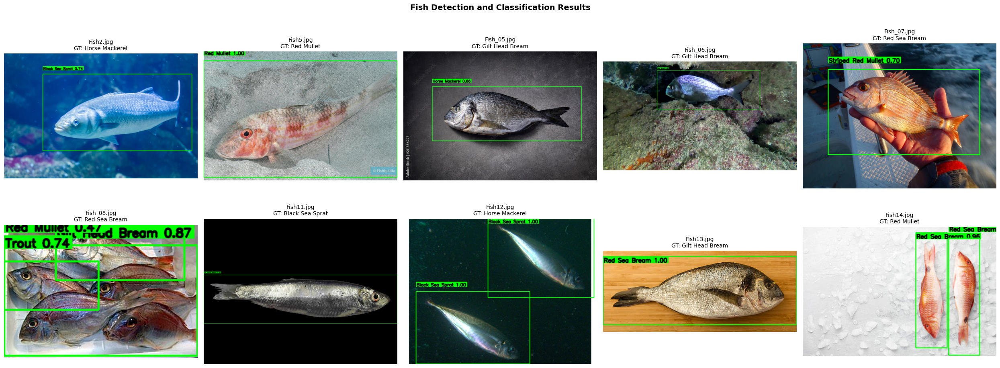

In [ ]:
# --- Visualization: Detection and Classification Results ---

BOX_COLOR = (0, 255, 0)
TEXT_COLOR = (0, 0, 0)
BOX_THICKNESS = 2
FONT = cv2.FONT_HERSHEY_SIMPLEX
FONT_SCALE = 0.6
FONT_THICKNESS = 2

n_images = len(all_det_results)
n_cols = min(5, n_images)
n_rows = (n_images + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows))
axes = np.array(axes).flatten() if n_images > 1 else [axes]

for idx, (img_name, det_results) in enumerate(all_det_results.items()):
    img_bgr = det_results[0].orig_img
    output_img = img_bgr.copy()
    preds = all_predictions.get(img_name, [])
    ground_truth = GROUND_TRUTH.get(img_name, "Unknown")

    for pred in preds:
        x1, y1, x2, y2 = map(int, pred["xyxy"])
        label = pred.get("cls_label", "Unknown")
        conf = pred.get("cls_conf", None)

        text = f"{label}" if conf is None else f"{label} {conf:.2f}"

        cv2.rectangle(output_img, (x1, y1), (x2, y2), BOX_COLOR, BOX_THICKNESS)

        (text_width, text_height), baseline = cv2.getTextSize(text, FONT, FONT_SCALE, FONT_THICKNESS)

        y_text = y1 - text_height - baseline
        if y_text < 0:
            y_text = y1 + text_height + baseline

        cv2.rectangle(output_img, (x1, y_text - text_height - baseline),
                      (x1 + text_width + 4, y_text), BOX_COLOR, -1)
        cv2.putText(output_img, text, (x1 + 2, y_text - 2), FONT, FONT_SCALE,
                    TEXT_COLOR, FONT_THICKNESS, cv2.LINE_AA)

    axes[idx].imshow(cv2.cvtColor(output_img, cv2.COLOR_BGR2RGB))
    axes[idx].axis("off")
    axes[idx].set_title(f"{img_name}\nGT: {ground_truth}", fontsize=10)

# Hide unused subplots
for idx in range(n_images, len(axes)):
    axes[idx].axis("off")

plt.suptitle("Fish Detection and Classification Results", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

The predictive reliability of the model degrades significantly when confronted with increased environmental and morphological complexity. The current architecture struggles to generalize across high-variance scenarios involving multiple overlapping subjects, atypical camera angles, or diverse aquatic habitats, and it fails to distinguish the subtle taxonomic nuances found in unseen subspecies.